Задача:
1. Обучить модели машинного обучения для прогноза модуля упругости при растяжении и прочности при растяжении;

2. Разработать нейронную сеть, которая будет рекомендовать соотношение матрица-наполнитель.

In [1]:
# Выполняем импорт необходимых библиотек

import pandas as pd
import numpy as np
import seaborn as sns

import scipy
from scipy import stats

import matplotlib.pyplot as plt

%matplotlib inline

import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import Normalizer, MinMaxScaler, StandardScaler, RobustScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, cross_validate, LeaveOneOut
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error, mean_absolute_error

import optuna
from optuna_integration import OptunaSearchCV
from optuna.distributions import (CategoricalDistribution, FloatDistribution, IntDistribution)

import skopt
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

import xgboost as xgb
from xgboost import XGBRegressor

import lightgbm as lgb
from lightgbm import LGBMRegressor

import shap

import tensorflow as tf
from tensorflow.keras import Sequential 
from tensorflow.keras import layers 
from tensorflow.keras.layers import Input, Dense, Activation, BatchNormalization, Dropout 
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau 
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

import warnings
warnings.filterwarnings('ignore')

## Считываем данные из таблиц Excel

In [3]:
df1 = pd.read_excel("X_bp.xlsx",  index_col=0)
df1.head()

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2"
0,1.857143,2030.0,738.736842,30.00,22.267857,100.000000,210.0,70.0,3000.0,220.0
1,1.857143,2030.0,738.736842,50.00,23.750000,284.615385,210.0,70.0,3000.0,220.0
2,1.857143,2030.0,738.736842,49.90,33.000000,284.615385,210.0,70.0,3000.0,220.0
3,1.857143,2030.0,738.736842,129.00,21.250000,300.000000,210.0,70.0,3000.0,220.0
4,2.771331,2030.0,753.000000,111.86,22.267857,284.615385,210.0,70.0,3000.0,220.0


При изучении данных ярко выражена граница между данными: первые 23 строки имеют иное происхождение, в отличие от остальных. 
При дальнейшем изучении сделан вывод о том, что эти 23 строки реальные данные, остальное синтетические данные.

In [5]:
df2 = pd.read_excel("X_nup.xlsx", index_col=0)
df2.head()

,"Угол нашивки, град",Шаг нашивки,Плотность нашивки
0,0,4.0,57.0
1,0,4.0,60.0
2,0,4.0,70.0
3,0,5.0,47.0
4,0,5.0,57.0


При изучении данных ярко выражена граница между данными: первые 40 строк имеют иное происхождение, в отличие от остальных. 
При дальнейшем изучении сделан вывод о том, что эти 40 строк реальные данные, остальное синтетические данные.

In [7]:
#Совмещаем данные в полученных датафреймах, так чтобы реальные данные максимально совместились

composed_mat = df1.join(df2, how='inner')
composed_mat

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки
0,1.857143,2030.000000,738.736842,30.000000,22.267857,100.000000,210.000000,70.000000,3000.000000,220.000000,0,4.000000,57.000000
1,1.857143,2030.000000,738.736842,50.000000,23.750000,284.615385,210.000000,70.000000,3000.000000,220.000000,0,4.000000,60.000000
2,1.857143,2030.000000,738.736842,49.900000,33.000000,284.615385,210.000000,70.000000,3000.000000,220.000000,0,4.000000,70.000000
3,1.857143,2030.000000,738.736842,129.000000,21.250000,300.000000,210.000000,70.000000,3000.000000,220.000000,0,5.000000,47.000000
4,2.771331,2030.000000,753.000000,111.860000,22.267857,284.615385,210.000000,70.000000,3000.000000,220.000000,0,5.000000,57.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1018,2.271346,1952.087902,912.855545,86.992183,20.123249,324.774576,209.198700,73.090961,2387.292495,125.007669,90,9.076380,47.019770
1019,3.444022,2050.089171,444.732634,145.981978,19.599769,254.215401,350.660830,72.920827,2360.392784,117.730099,90,10.565614,53.750790
1020,3.280604,1972.372865,416.836524,110.533477,23.957502,248.423047,740.142791,74.734344,2662.906040,236.606764,90,4.161154,67.629684
1021,3.705351,2066.799773,741.475517,141.397963,19.246945,275.779840,641.468152,74.042708,2071.715856,197.126067,90,6.313201,58.261074


## Проводим EDA в полученном датафрейме

In [9]:
# Просмотр информации о заполненности колонок и типе данных, содержащихся там

composed_mat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1023 entries, 0 to 1022
Data columns (total 13 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Соотношение матрица-наполнитель       1023 non-null   float64
 1   Плотность, кг/м3                      1023 non-null   float64
 2   модуль упругости, ГПа                 1023 non-null   float64
 3   Количество отвердителя, м.%           1023 non-null   float64
 4   Содержание эпоксидных групп,%_2       1023 non-null   float64
 5   Температура вспышки, С_2              1023 non-null   float64
 6   Поверхностная плотность, г/м2         1023 non-null   float64
 7   Модуль упругости при растяжении, ГПа  1023 non-null   float64
 8   Прочность при растяжении, МПа         1023 non-null   float64
 9   Потребление смолы, г/м2               1023 non-null   float64
 10  Угол нашивки, град                    1023 non-null   int64  
 11  Шаг нашивки           

В данных пропусков нет, все переменные в числовом формате - float64, int.

In [11]:
# Получаем статистическую информацию о датафрейме

composed_mat.describe()

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки
count,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000,1023.000000
mean,2.930366,1975.734888,739.923233,110.570769,22.244390,285.882151,482.731833,73.328571,2466.922843,218.423144,44.252199,6.899222,57.153929
std,0.913222,73.729231,330.231581,28.295911,2.406301,40.943260,281.314690,3.118983,485.628006,59.735931,45.015793,2.563467,12.350969
min,0.389403,1731.764635,2.436909,17.740275,14.254985,100.000000,0.603740,64.054061,1036.856605,33.803026,0.000000,0.000000,0.000000
25%,2.317887,1924.155467,500.047452,92.443497,20.608034,259.066528,266.816645,71.245018,2135.850448,179.627520,0.000000,5.080033,49.799212
50%,2.906878,1977.621657,739.664328,110.564840,22.230744,285.896812,451.864365,73.268805,2459.524526,219.198882,0.000000,6.916144,57.341920
75%,3.552660,2021.374375,961.812526,129.730366,23.961934,313.002106,693.225017,75.356612,2767.193119,257.481724,90.000000,8.586293,64.944961
max,5.591742,2207.773481,1911.536477,198.953207,33.000000,413.273418,1399.542362,82.682051,3848.436732,414.590628,90.000000,14.440522,103.988901


In [13]:
# Поиск уникальных значений с помощью функции nunique
composed_mat.nunique()

Соотношение матрица-наполнитель         1014
Плотность, кг/м3                        1013
модуль упругости, ГПа                   1020
Количество отвердителя, м.%             1005
Содержание эпоксидных групп,%_2         1004
Температура вспышки, С_2                1003
Поверхностная плотность, г/м2           1004
Модуль упругости при растяжении, ГПа    1004
Прочность при растяжении, МПа           1004
Потребление смолы, г/м2                 1003
Угол нашивки, град                         2
Шаг нашивки                              989
Плотность нашивки                        988
dtype: int64

In [9]:
# Уточним значения угла нашивки
composed_mat["Угол нашивки, град"].unique()

array([ 0, 90], dtype=int64)

In [9]:
# Угол нашивки имеет только два значения 0 и 90 градусов
# Заменим их на значения синуса для этих углов

composed_mat["Cинус угла нашивки"] = np.sin(np.radians(composed_mat["Угол нашивки, град"])).round(6)
composed_mat = composed_mat.drop(columns=["Угол нашивки, град"])
composed_mat.head()

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2",Шаг нашивки,Плотность нашивки,Cинус угла нашивки
0,1.857143,2030.0,738.736842,30.00,22.267857,100.000000,210.0,70.0,3000.0,220.0,4.0,57.0,0.0
1,1.857143,2030.0,738.736842,50.00,23.750000,284.615385,210.0,70.0,3000.0,220.0,4.0,60.0,0.0
2,1.857143,2030.0,738.736842,49.90,33.000000,284.615385,210.0,70.0,3000.0,220.0,4.0,70.0,0.0
3,1.857143,2030.0,738.736842,129.00,21.250000,300.000000,210.0,70.0,3000.0,220.0,5.0,47.0,0.0
4,2.771331,2030.0,753.000000,111.86,22.267857,284.615385,210.0,70.0,3000.0,220.0,5.0,57.0,0.0


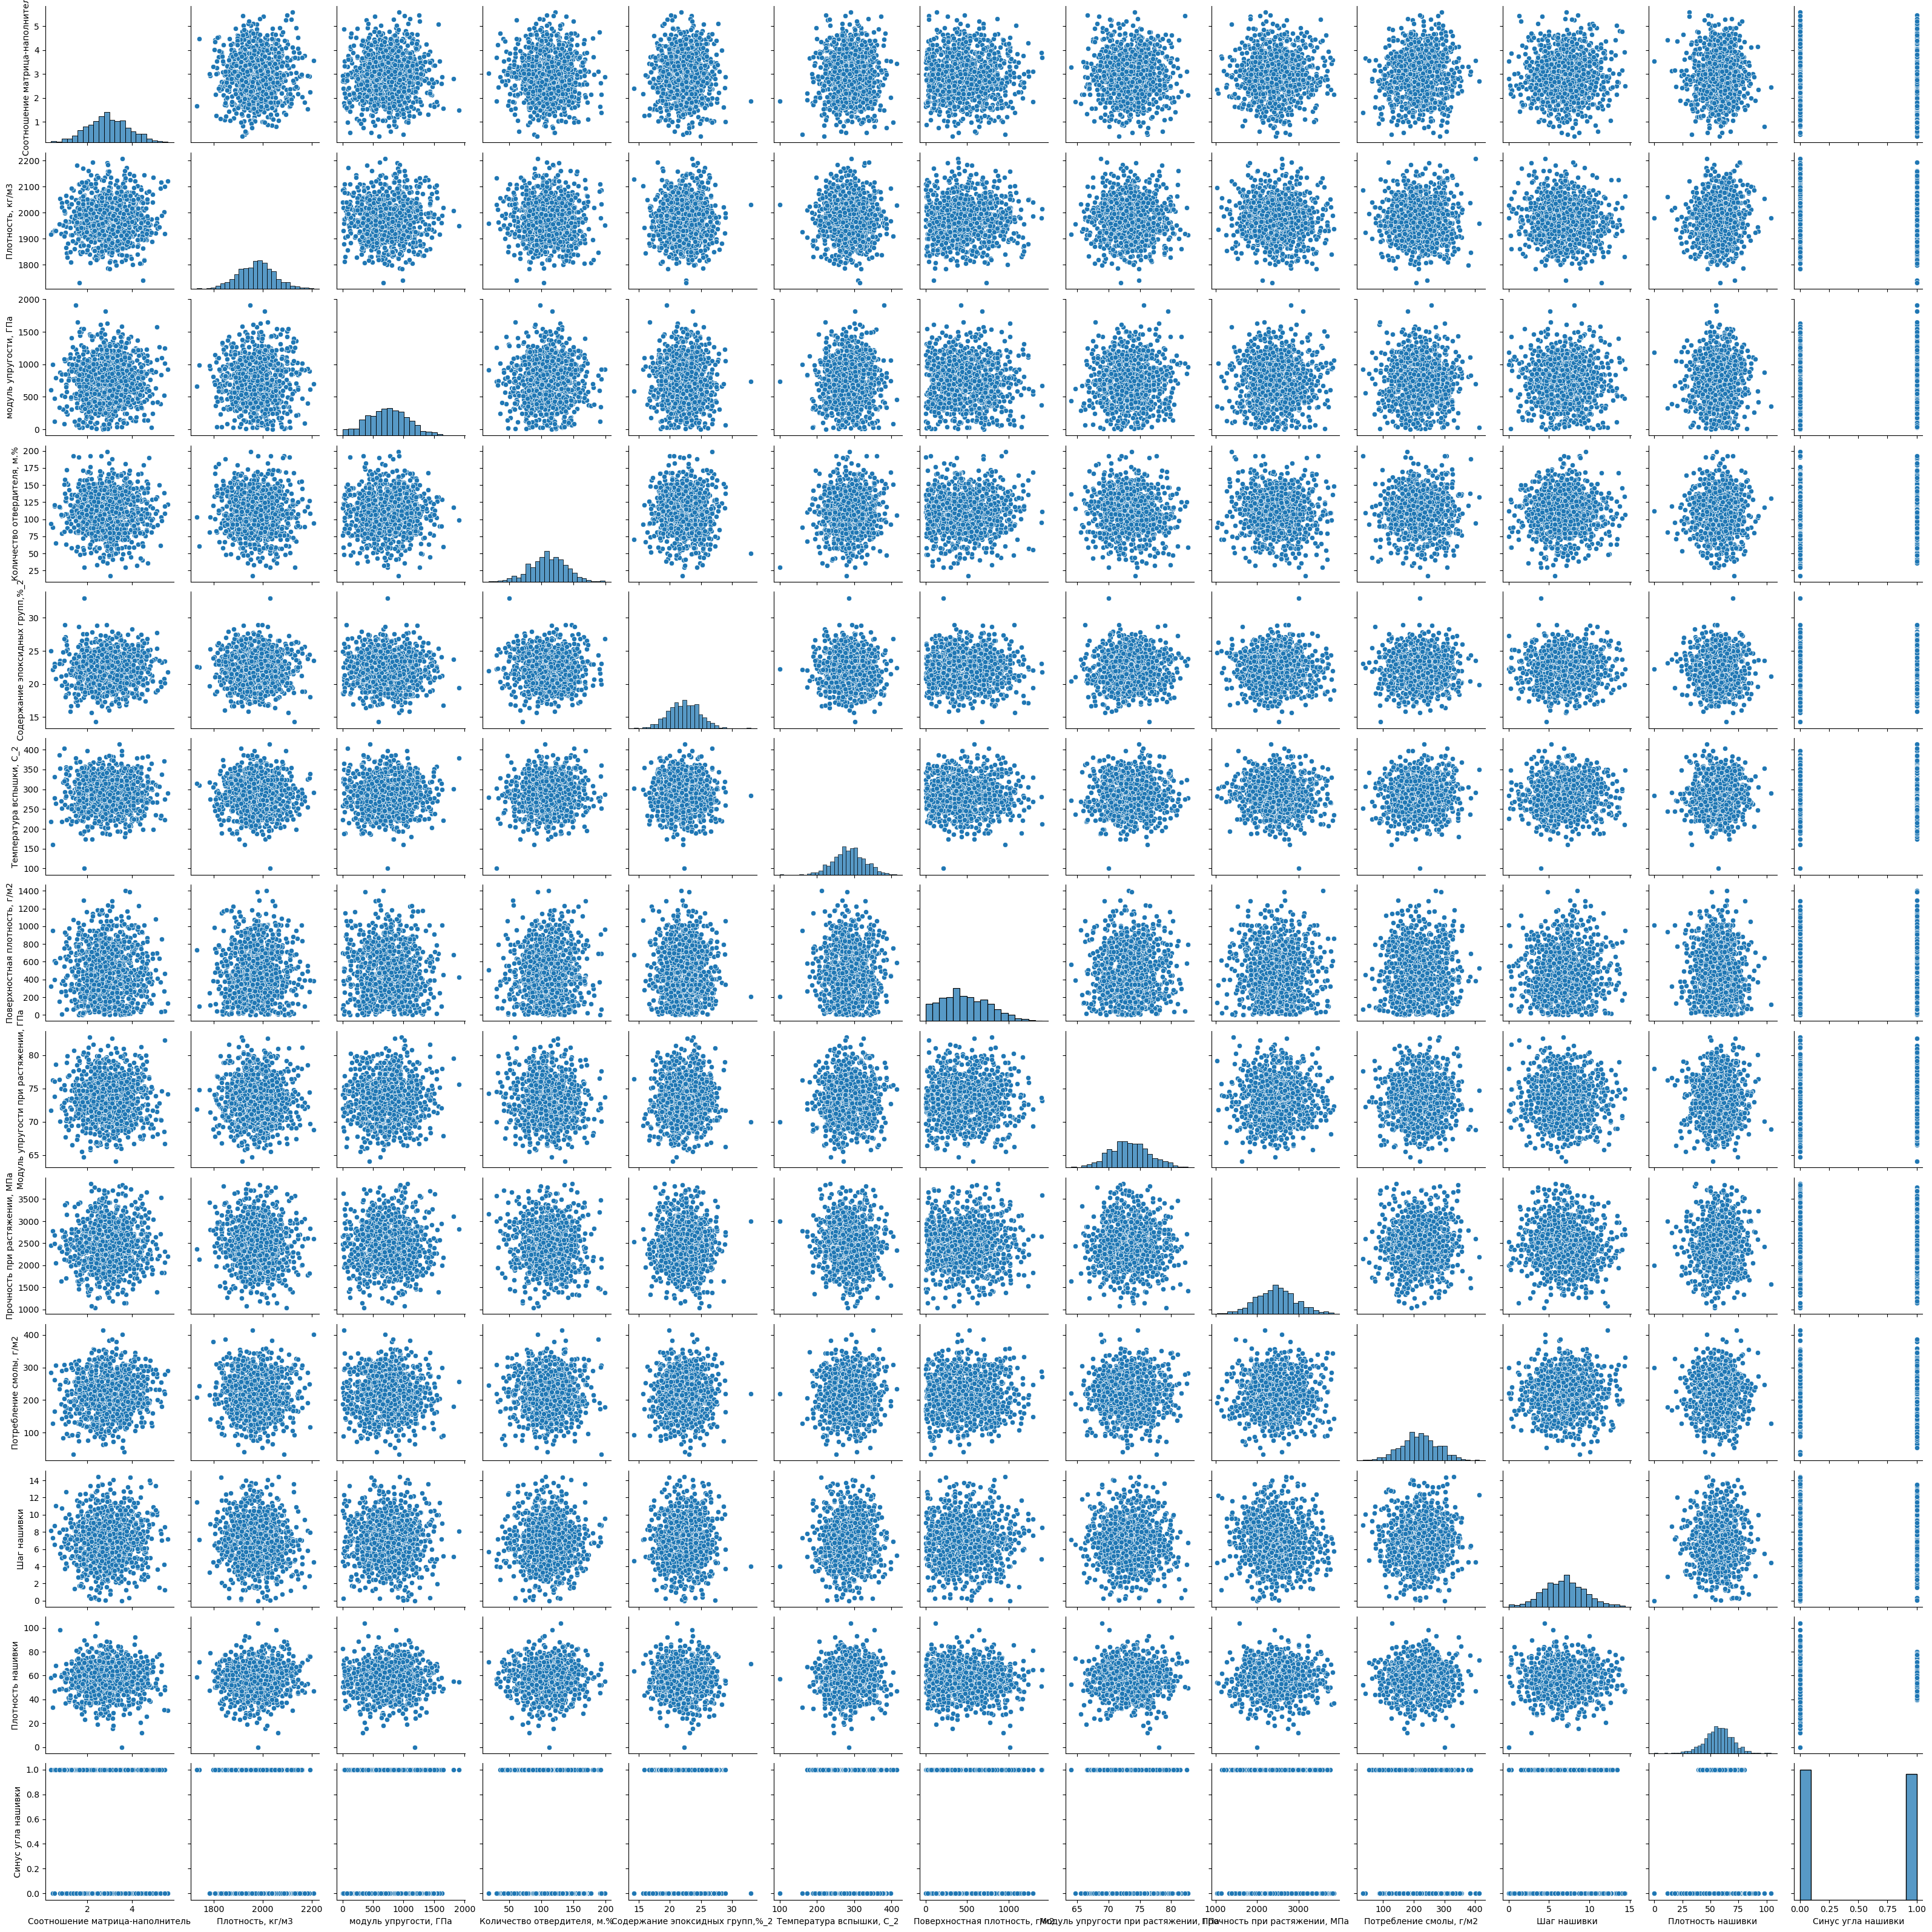

In [11]:
# Смотрим парные зависимости данных

selected_palette = sns.color_palette("hls", 8)
sns.pairplot (composed_mat, palette=selected_palette[5])

Исходя из точечных диаграмм: данные между собой практически не коррелируются, разброс похож на случайный.

In [21]:
# Данные нормально распределены, но четких зависимостей не просматривается
# Проверим корреляцию данных: строим матрицу корреляции по методу Пирсона

CM_corr_matrix = composed_mat.corr()
CM_corr_matrix

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2",Шаг нашивки,Плотность нашивки,Cинус угла нашивки
Соотношение матрица-наполнитель,1.000000,0.003841,0.031700,-0.006445,0.019766,-0.004776,-0.006272,-0.008411,0.024148,0.072531,0.036437,-0.004652,-0.031073
"Плотность, кг/м3",0.003841,1.000000,-0.009647,-0.035911,-0.008278,-0.020695,0.044930,-0.017602,-0.069981,-0.015937,-0.061015,0.080304,-0.068474
"модуль упругости, ГПа",0.031700,-0.009647,1.000000,0.024049,-0.006804,0.031174,-0.005306,0.023267,0.041868,0.001840,-0.009875,0.056346,-0.025417
"Количество отвердителя, м.%",-0.006445,-0.035911,0.024049,1.000000,-0.000684,0.095193,0.055198,-0.065929,-0.075375,0.007446,0.014887,0.017248,0.038570
"Содержание эпоксидных групп,%_2",0.019766,-0.008278,-0.006804,-0.000684,1.000000,-0.009769,-0.012940,0.056828,-0.023899,0.015165,0.003022,-0.039073,0.008052
"Температура вспышки, С_2",-0.004776,-0.020695,0.031174,0.095193,-0.009769,1.000000,0.020121,0.028414,-0.031763,0.059954,0.025795,0.011391,0.020695
"Поверхностная плотность, г/м2",-0.006272,0.044930,-0.005306,0.055198,-0.012940,0.020121,1.000000,0.036702,-0.003210,0.015692,0.038332,-0.049923,0.052299
"Модуль упругости при растяжении, ГПа",-0.008411,-0.017602,0.023267,-0.065929,0.056828,0.028414,0.036702,1.000000,-0.009009,0.050938,-0.029468,0.006476,0.023003
"Прочность при растяжении, МПа",0.024148,-0.069981,0.041868,-0.075375,-0.023899,-0.031763,-0.003210,-0.009009,1.000000,0.028602,-0.059547,0.019604,0.023398
"Потребление смолы, г/м2",0.072531,-0.015937,0.001840,0.007446,0.015165,0.059954,0.015692,0.050938,0.028602,1.000000,0.013394,0.012239,-0.015334


Значения коэффициентов корреляции близки к нулю, что говорит об очень слабых линейных зависимостях между переменными

In [24]:
# Проверим корреляцию данных: строим матрицу корреляции по методу Спирмена

Matr_spearman = composed_mat.corr(method='spearman')
Matr_spearman

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2",Шаг нашивки,Плотность нашивки,Cинус угла нашивки
Соотношение матрица-наполнитель,1.000000,-0.005542,0.031823,0.002496,0.016358,-0.013635,-0.003896,-0.006459,0.017554,0.054084,0.032510,0.004570,-0.026190
"Плотность, кг/м3",-0.005542,1.000000,-0.010097,-0.032907,-0.012287,-0.030447,0.055071,-0.032446,-0.069816,-0.025729,-0.045941,0.080001,-0.063073
"модуль упругости, ГПа",0.031823,-0.010097,1.000000,0.033397,0.002016,0.031247,-0.001318,0.007705,0.033750,0.008010,-0.011851,0.072628,-0.038800
"Количество отвердителя, м.%",0.002496,-0.032907,0.033397,1.000000,-0.001652,0.086970,0.050751,-0.064127,-0.067707,-0.006371,0.008440,0.025265,0.030222
"Содержание эпоксидных групп,%_2",0.016358,-0.012287,0.002016,-0.001652,1.000000,-0.003641,-0.011232,0.061930,-0.019193,0.014230,-0.007421,-0.032182,0.005714
"Температура вспышки, С_2",-0.013635,-0.030447,0.031247,0.086970,-0.003641,1.000000,0.025441,0.024625,-0.028283,0.051763,0.043075,0.008160,0.021886
"Поверхностная плотность, г/м2",-0.003896,0.055071,-0.001318,0.050751,-0.011232,0.025441,1.000000,0.035319,-0.008221,-0.005344,0.037675,-0.032404,0.055637
"Модуль упругости при растяжении, ГПа",-0.006459,-0.032446,0.007705,-0.064127,0.061930,0.024625,0.035319,1.000000,-0.009970,0.052450,-0.014210,-0.003225,0.027458
"Прочность при растяжении, МПа",0.017554,-0.069816,0.033750,-0.067707,-0.019193,-0.028283,-0.008221,-0.009970,1.000000,0.020831,-0.071915,0.014950,0.025226
"Потребление смолы, г/м2",0.054084,-0.025729,0.008010,-0.006371,0.014230,0.051763,-0.005344,0.052450,0.020831,1.000000,0.009288,0.016236,-0.002940


В этой матрице значения коэффициентов низкие, нелинейные зависимости также есть и они тоже очень слабые

<Axes: >

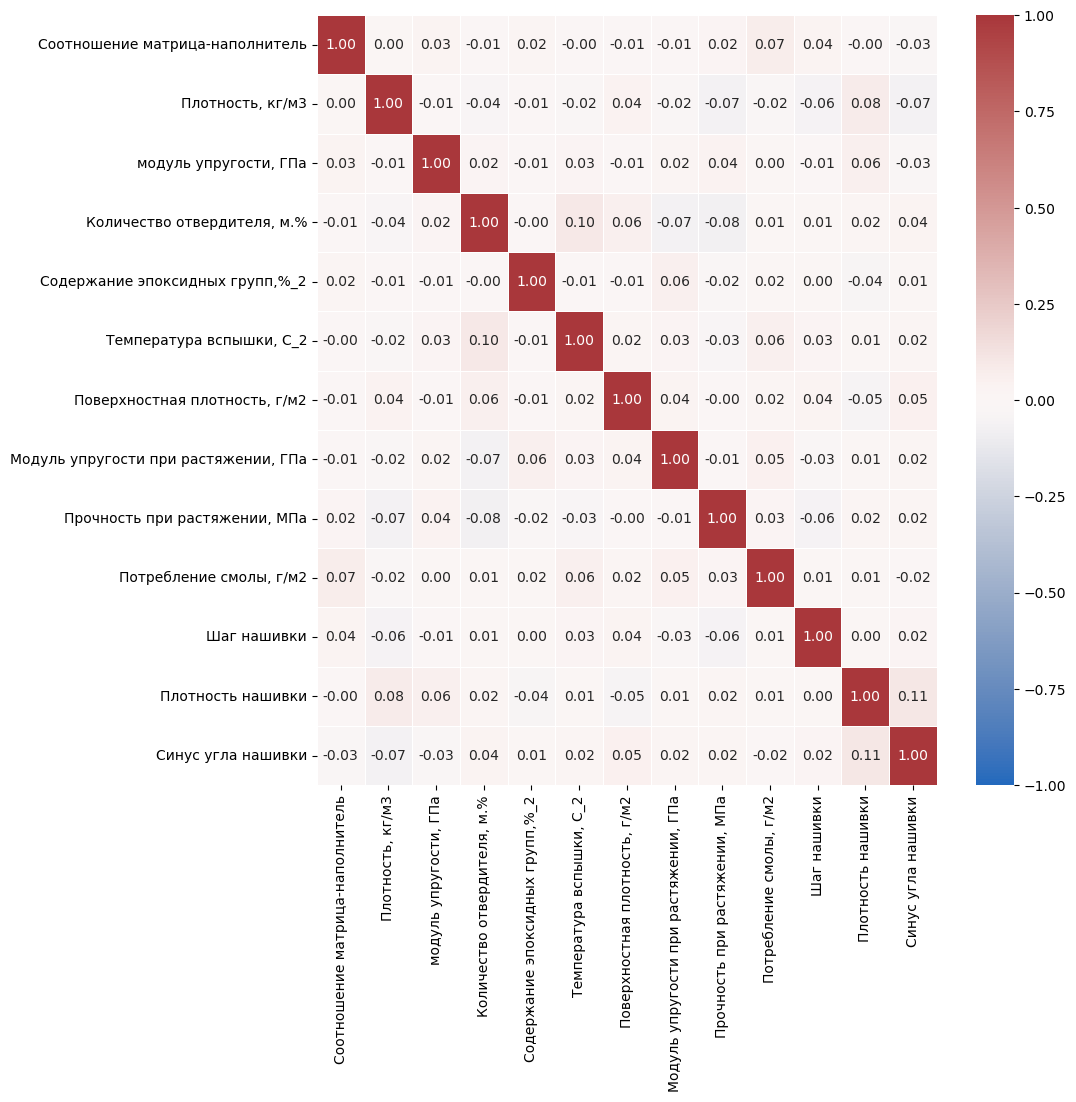

In [27]:
# Для удобства анализа корреляции построим тепловые карты для корреляции по методу Пирсона и по методу Спирмена

plt.figure(figsize=(10, 10))
sns.heatmap(data = CM_corr_matrix, cmap = "vlag", annot=True, vmin=-1, vmax=1, center=0, fmt='.2f', linewidths=0.5, cbar = True)

<Axes: >

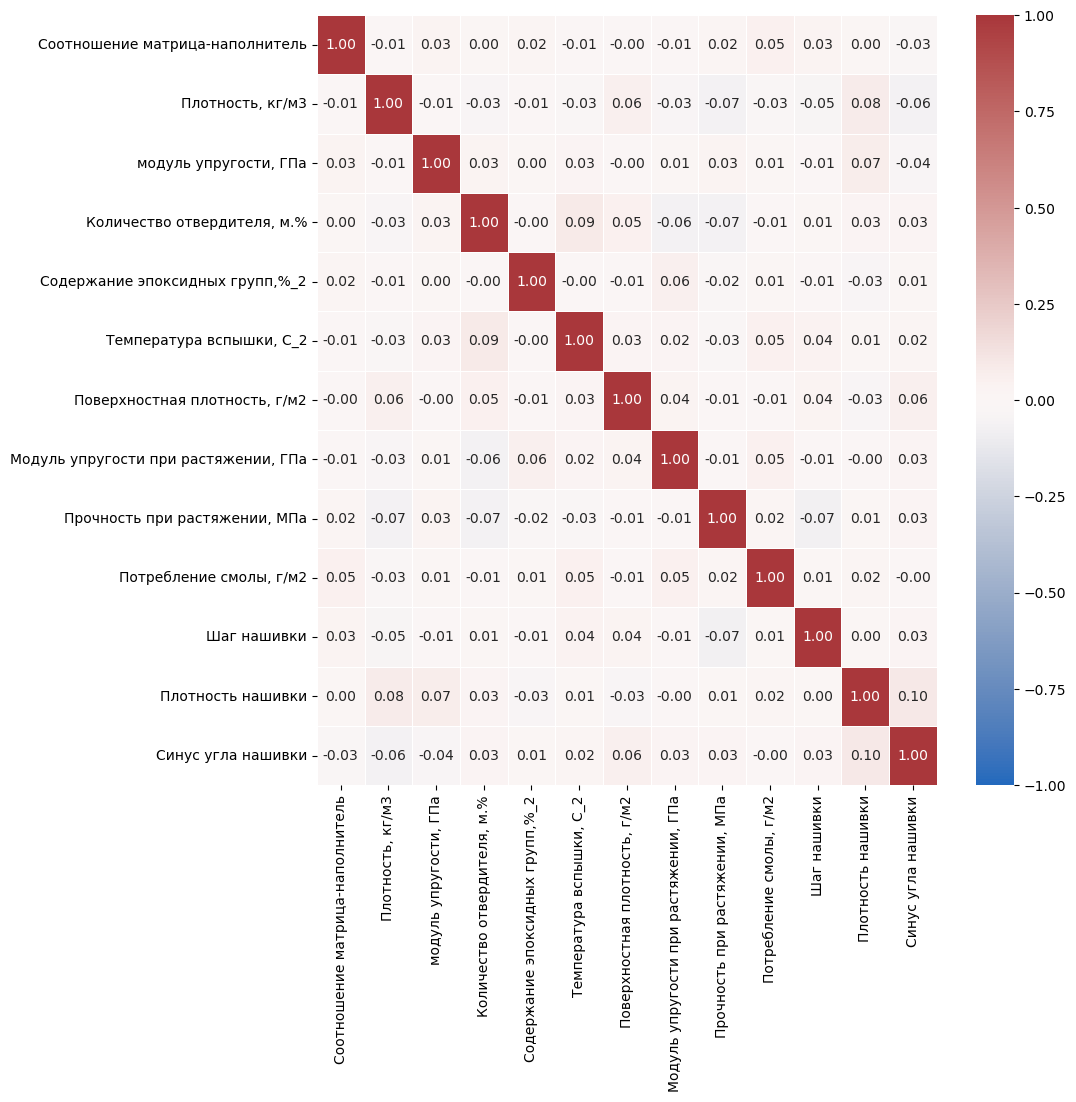

In [29]:
plt.figure(figsize=(10, 10))
sns.heatmap(data = Matr_spearman, cmap = "vlag", annot=True, vmin=-1, vmax=1, center=0, fmt='.2f', linewidths=0.5, cbar = True)

Text(0.5, 1.0, 'Коррелляция по Спирмену')

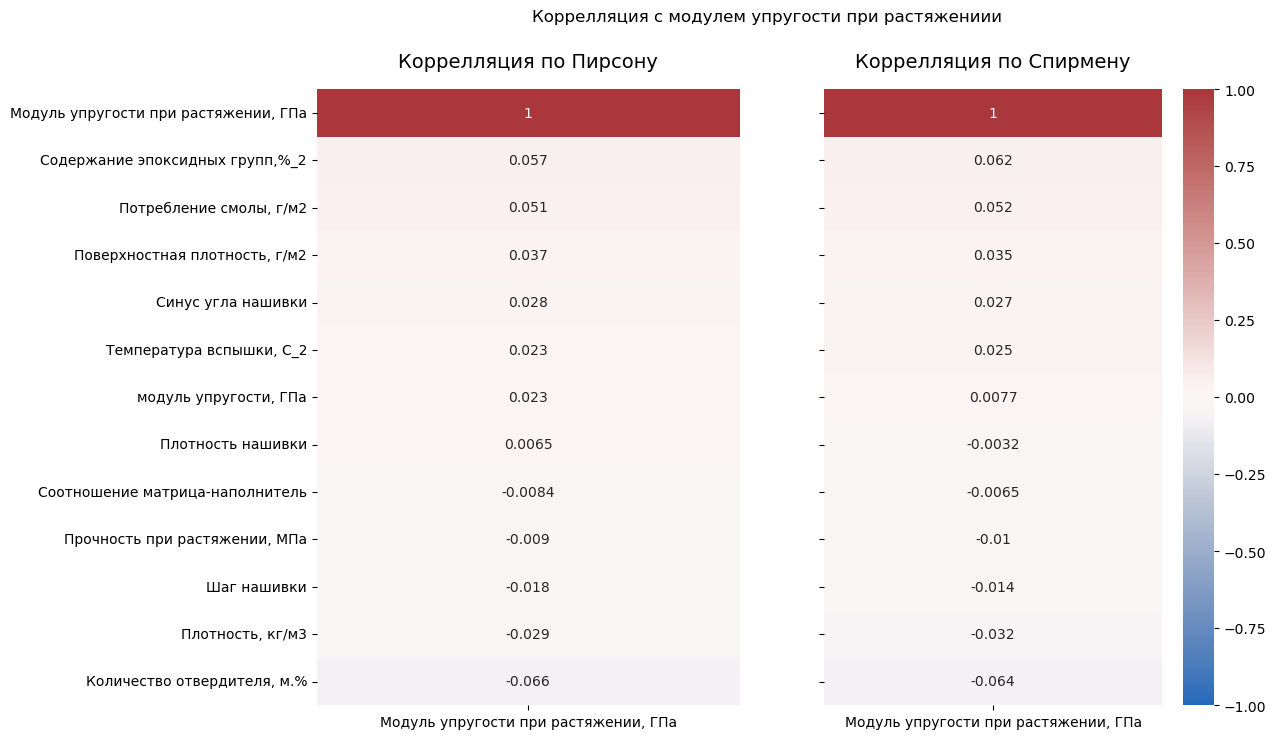

In [31]:
# Строим тепловые карты с выборкой коэффициентов относительно целевых переменных

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
fig.suptitle('Коррелляция с модулем упругости при растяжениии')

tgt1_heatmap = sns.heatmap(CM_corr_matrix[['Модуль упругости при растяжении, ГПа']].sort_values(by='Модуль упругости при растяжении, ГПа', ascending=False), ax=axes[0], cbar=False, vmin=-1, vmax=1, annot=True, cmap='vlag')
tgt1_heatmap.set_title('Коррелляция по Пирсону', fontdict={'fontsize':14}, pad=16)

tgt3_heatmap = sns.heatmap(Matr_spearman[['Модуль упругости при растяжении, ГПа']].sort_values(by='Модуль упругости при растяжении, ГПа', ascending=False), ax=axes[1], vmin=-1, vmax=1, annot=True, cmap='vlag')
tgt3_heatmap.set_title('Коррелляция по Спирмену', fontdict={'fontsize':14}, pad=16)

Text(0.5, 1.0, 'Коррелляция по Пирсону')

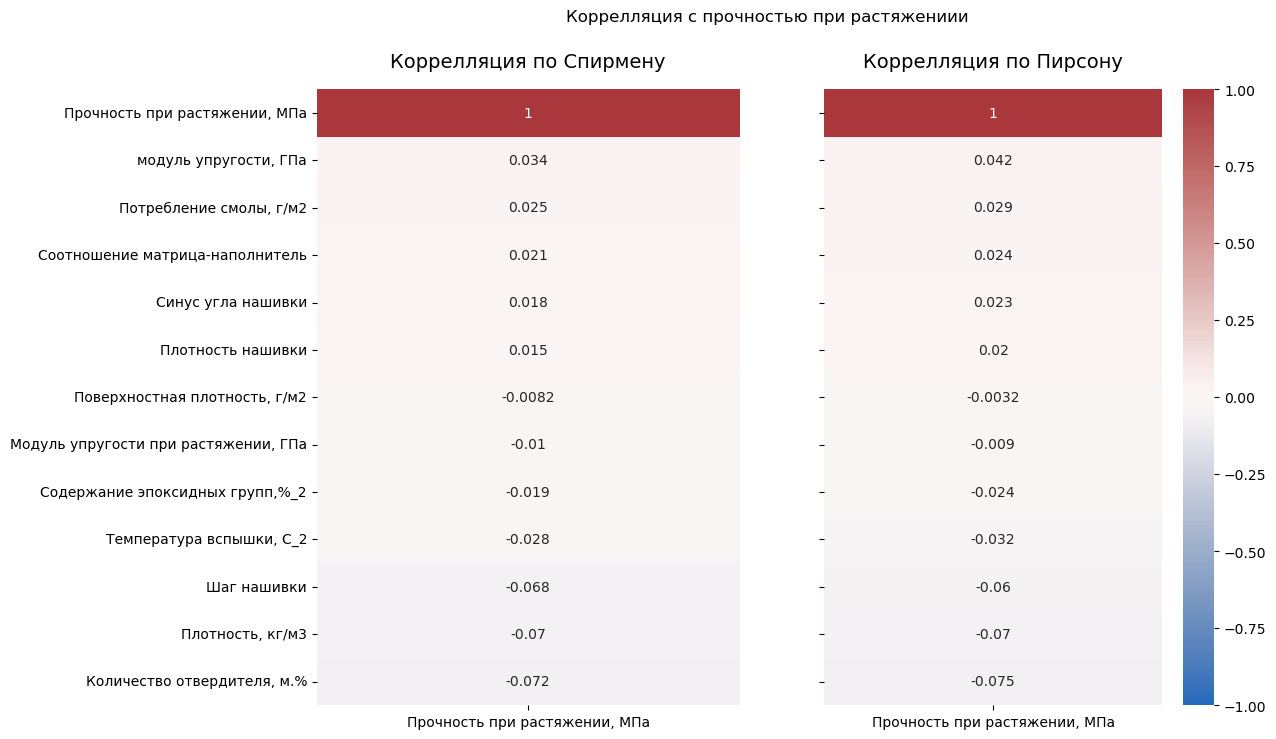

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
fig.suptitle('Коррелляция с прочностью при растяжениии')

tgt2_heatmap = sns.heatmap(Matr_spearman[['Прочность при растяжении, МПа']].sort_values(by='Прочность при растяжении, МПа', ascending=False), ax=axes[0], cbar=False, vmin=-1, vmax=1, annot=True, cmap='vlag')
tgt2_heatmap.set_title('Коррелляция по Спирмену', fontdict={'fontsize':14}, pad=16)

tgt4_heatmap = sns.heatmap(CM_corr_matrix[['Прочность при растяжении, МПа']].sort_values(by='Прочность при растяжении, МПа', ascending=False), ax=axes[1], vmin=-1, vmax=1, annot=True, cmap='vlag')
tgt4_heatmap.set_title('Коррелляция по Пирсону', fontdict={'fontsize':14}, pad=16)

В датасете имеются очень слабые зависимости как линейного так и нелинейного характера

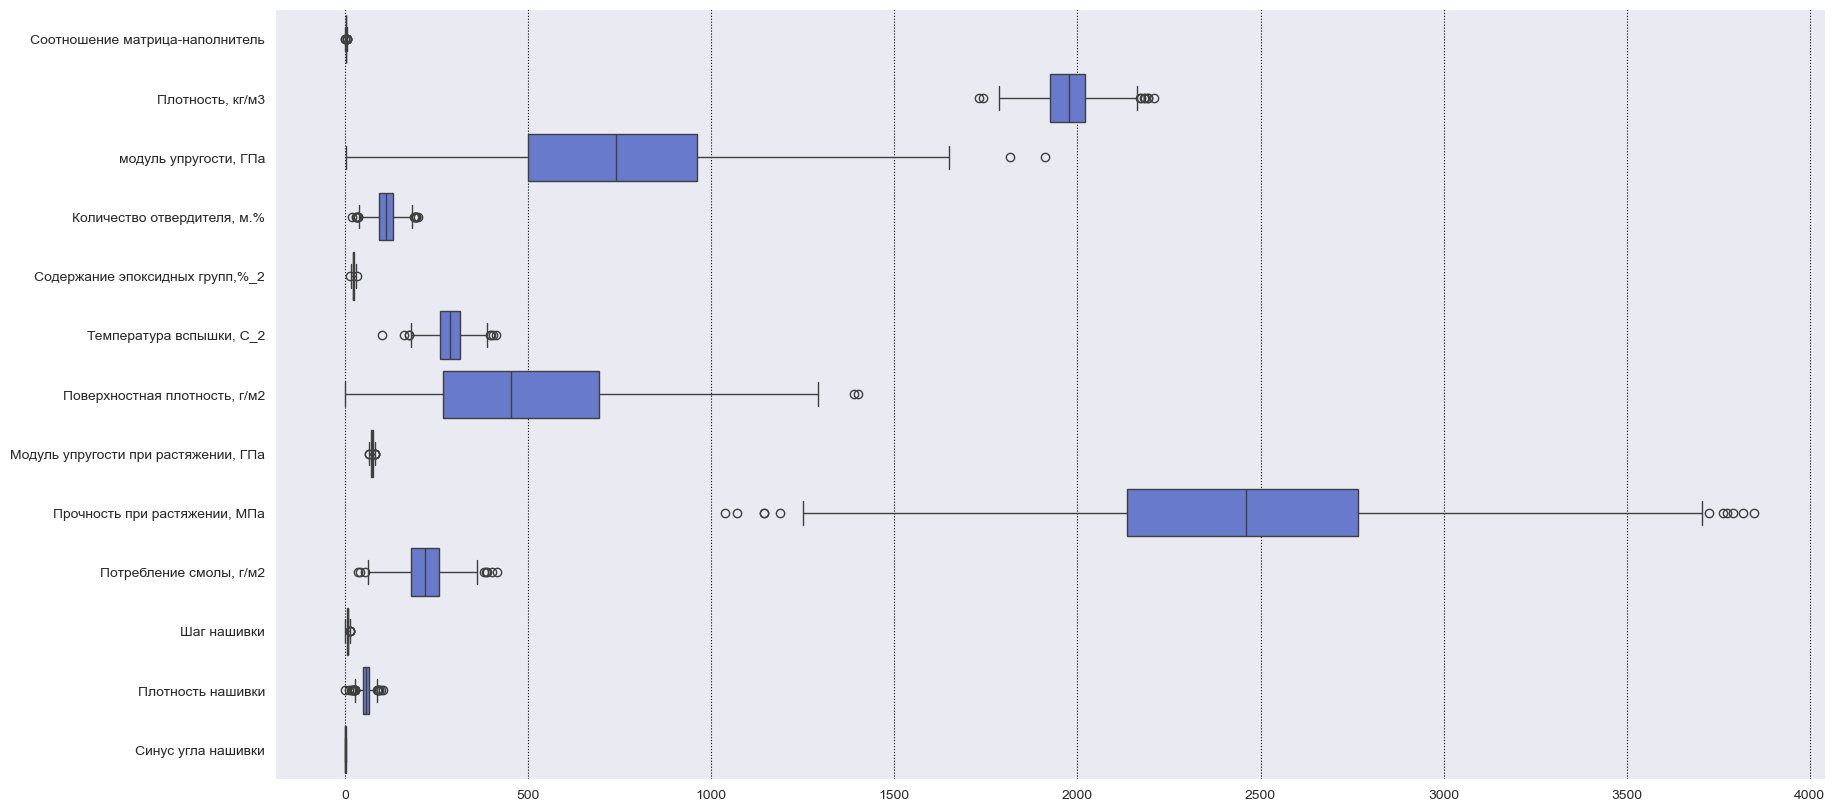

In [36]:
# Проверим наличие выбросов в данных

plt.figure(figsize=(20,10))
sns.set_style("darkgrid", {"grid.color":"0", "grid.linestyle":":"})
sns.boxplot(data = composed_mat, color=selected_palette[5], orient='h')
plt.show()

In [13]:
# В имеющихся данных имеются выбросы
# Выполним итеративную чистку выыбросов, с первого раза все не удаляются

print(f'Старый размер: {composed_mat.shape[0]}')

REAL_IDX = set(range(23))
df_mat   = composed_mat.copy()

iteration = 0

while True:
    Q1  = df_mat.quantile(0.25)
    Q3  = df_mat.quantile(0.75)
    IQR = Q3 - Q1

    outlier_mask = (
        (df_mat < (Q1 - 1.5 * IQR)) |
        (df_mat > (Q3 + 1.5 * IQR))
    ).any(axis=1)

    # Защита реальных строк
    real_mask    = df_mat.index.isin(REAL_IDX)
    outlier_mask = outlier_mask & ~real_mask

    n_outliers = outlier_mask.sum()
    iteration += 1
    
    print(f'  Итерация {iteration}: найдено выбросов — {n_outliers}')

    if n_outliers == 0:
        break

    df_mat = df_mat[~outlier_mask]

CM_clean = df_mat

CM_clean.reset_index(drop=True, inplace=True)

print(f'\nНовый размер: {CM_clean.shape[0]}')
print(f'\nУдалено {composed_mat.shape[0] - CM_clean.shape[0]} выбросов')
print(f'Реальных строк сохранено: {CM_clean.index.isin(REAL_IDX).sum()} из {len(REAL_IDX)}')

Старый размер: 1023
  Итерация 1: найдено выбросов — 84
  Итерация 2: найдено выбросов — 9
  Итерация 3: найдено выбросов — 3
  Итерация 4: найдено выбросов — 0

Новый размер: 927

Удалено 96 выбросов
Реальных строк сохранено: 23 из 23


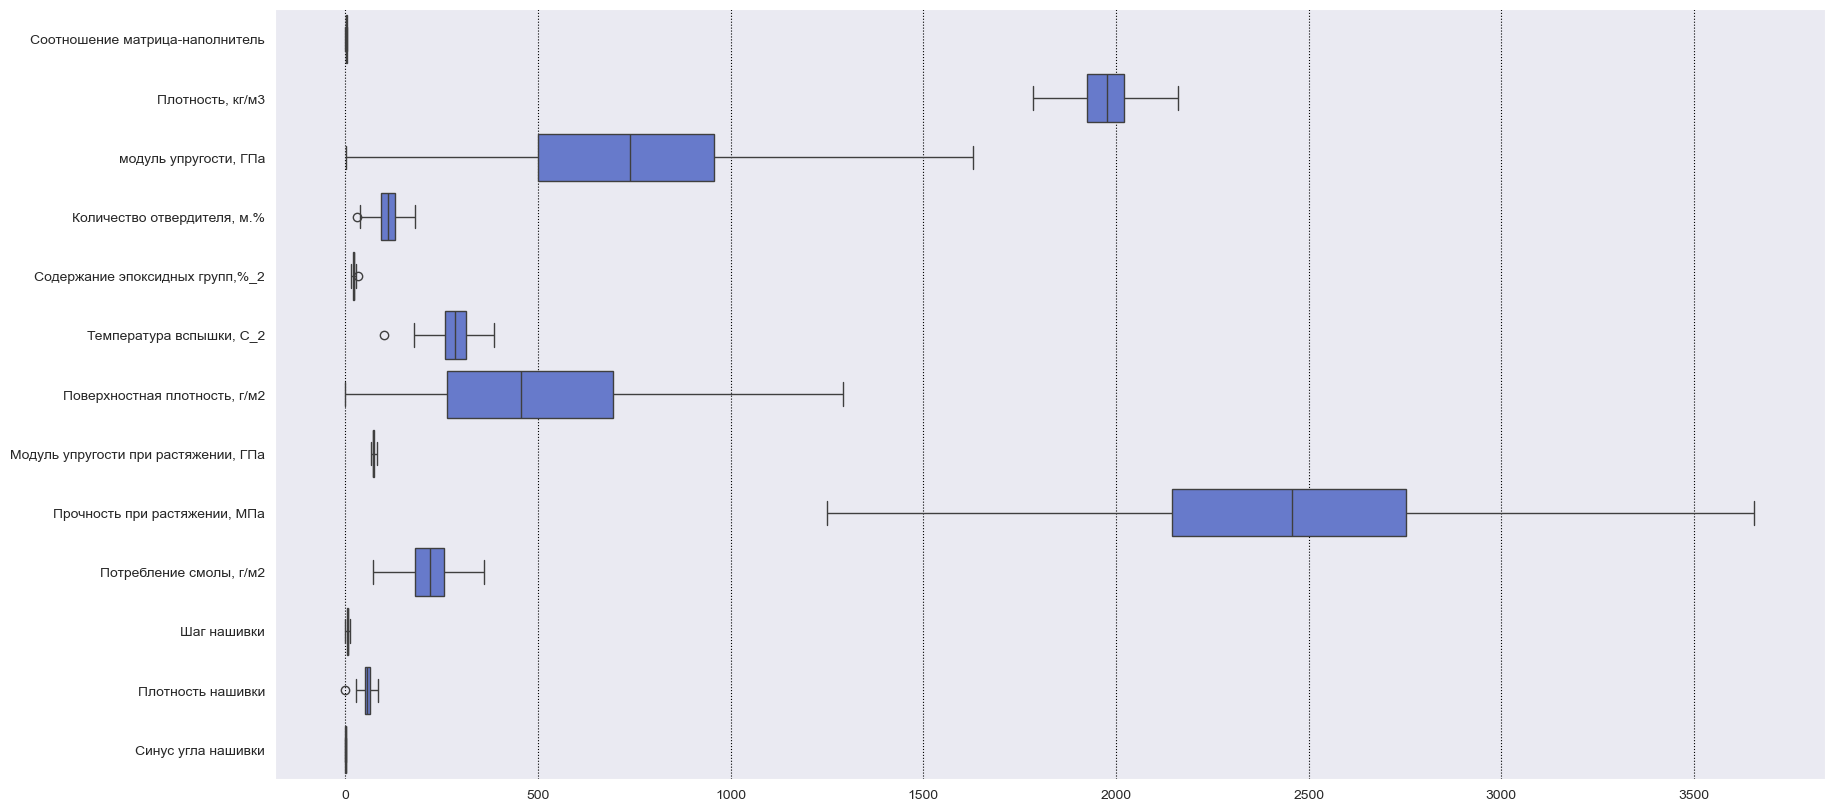

In [15]:
# Повторно проверим наличие выбросов после чистки
 
plt.figure(figsize=(20,10))
sns.set_style("darkgrid", {"grid.color":"0", "grid.linestyle":":"})
sns.boxplot(data = CM_clean, color=selected_palette[5], orient='h')
plt.show()

Оставшиеся выбросы находятся в защищаемых строках реальных данных.
Их нельзя удалять, чтобы не терять ценную фактическую информацию. 
Эти выбросы будут трактоваться как уникальные экспериментальные значения.

In [43]:
# Методом главных компонент определим как объясняется дисперсия данных в очищенном датасете

pca_data = PCA(n_components=13)
pca_data.fit(CM_clean)

evr = pca_data.explained_variance_ratio_
cvr = np.cumsum(pca_data.explained_variance_ratio_)
pca_df = pd.DataFrame()
pca_df['Дисперсия накопительно'] = cvr
pca_df['Объясненная дисперсия'] = evr
display(pca_df.head(13))

,Дисперсия накопительно,Объясненная дисперсия
0,0.514772,5.147715e-01
1,0.779210,2.644386e-01
2,0.973533,1.943234e-01
3,0.985877,1.234326e-02
4,0.993980,8.103376e-03
5,0.997886,3.906146e-03
6,0.999636,1.750126e-03
7,0.999945,3.084752e-04
8,0.999968,2.271687e-05
9,0.999983,1.557604e-05


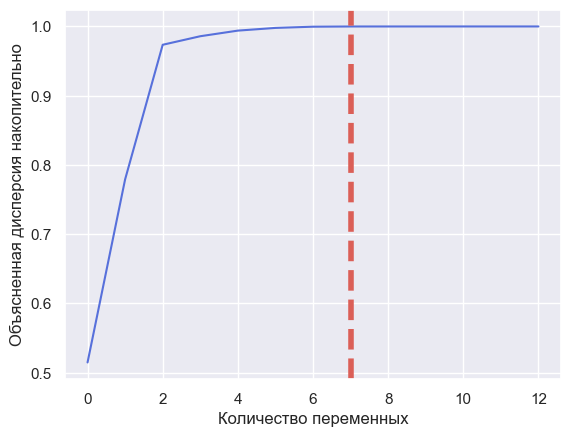

None

In [45]:
# Выведем зависимость объясненной дисперсии от количества переменных

sns.set(style='darkgrid')
plt.plot(np.cumsum(pca_data.explained_variance_ratio_), color=selected_palette[5])
plt.xlabel('Количество переменных')
plt.ylabel('Объясненная дисперсия накопительно')
plt.axvline(linewidth=4, color=selected_palette[0], linestyle = '--', x=7, ymin=0, ymax=1)
display(plt.show())

7 переменных могут объяснить 99,9% дисперсии

4 переменных объяснят 98,6% дисперсии

In [47]:
# в соответствии с заданием получаем минимумы и максимумы значений каждой переменной

maximums1 = CM_clean.max()
minimums1 = CM_clean.min()

print(f'Максимумы значений: {maximums1}')
print(f'Минимумы значений: {minimums1}')

Максимумы значений: Соотношение матрица-наполнитель            5.314144
Плотность, кг/м3                        2161.565216
модуль упругости, ГПа                   1628.000000
Количество отвердителя, м.%              181.828448
Содержание эпоксидных групп,%_2           33.000000
Температура вспышки, С_2                 386.067992
Поверхностная плотность, г/м2           1291.340115
Модуль упругости при растяжении, ГПа      81.417126
Прочность при растяжении, МПа           3656.158363
Потребление смолы, г/м2                  359.052220
Шаг нашивки                               13.732404
Плотность нашивки                         86.012427
Cинус угла нашивки                         1.000000
dtype: float64
Минимумы значений: Соотношение матрица-наполнитель            0.547391
Плотность, кг/м3                        1784.482245
модуль упругости, ГПа                      2.436909
Количество отвердителя, м.%               30.000000
Содержание эпоксидных групп,%_2           15.695894
Температур

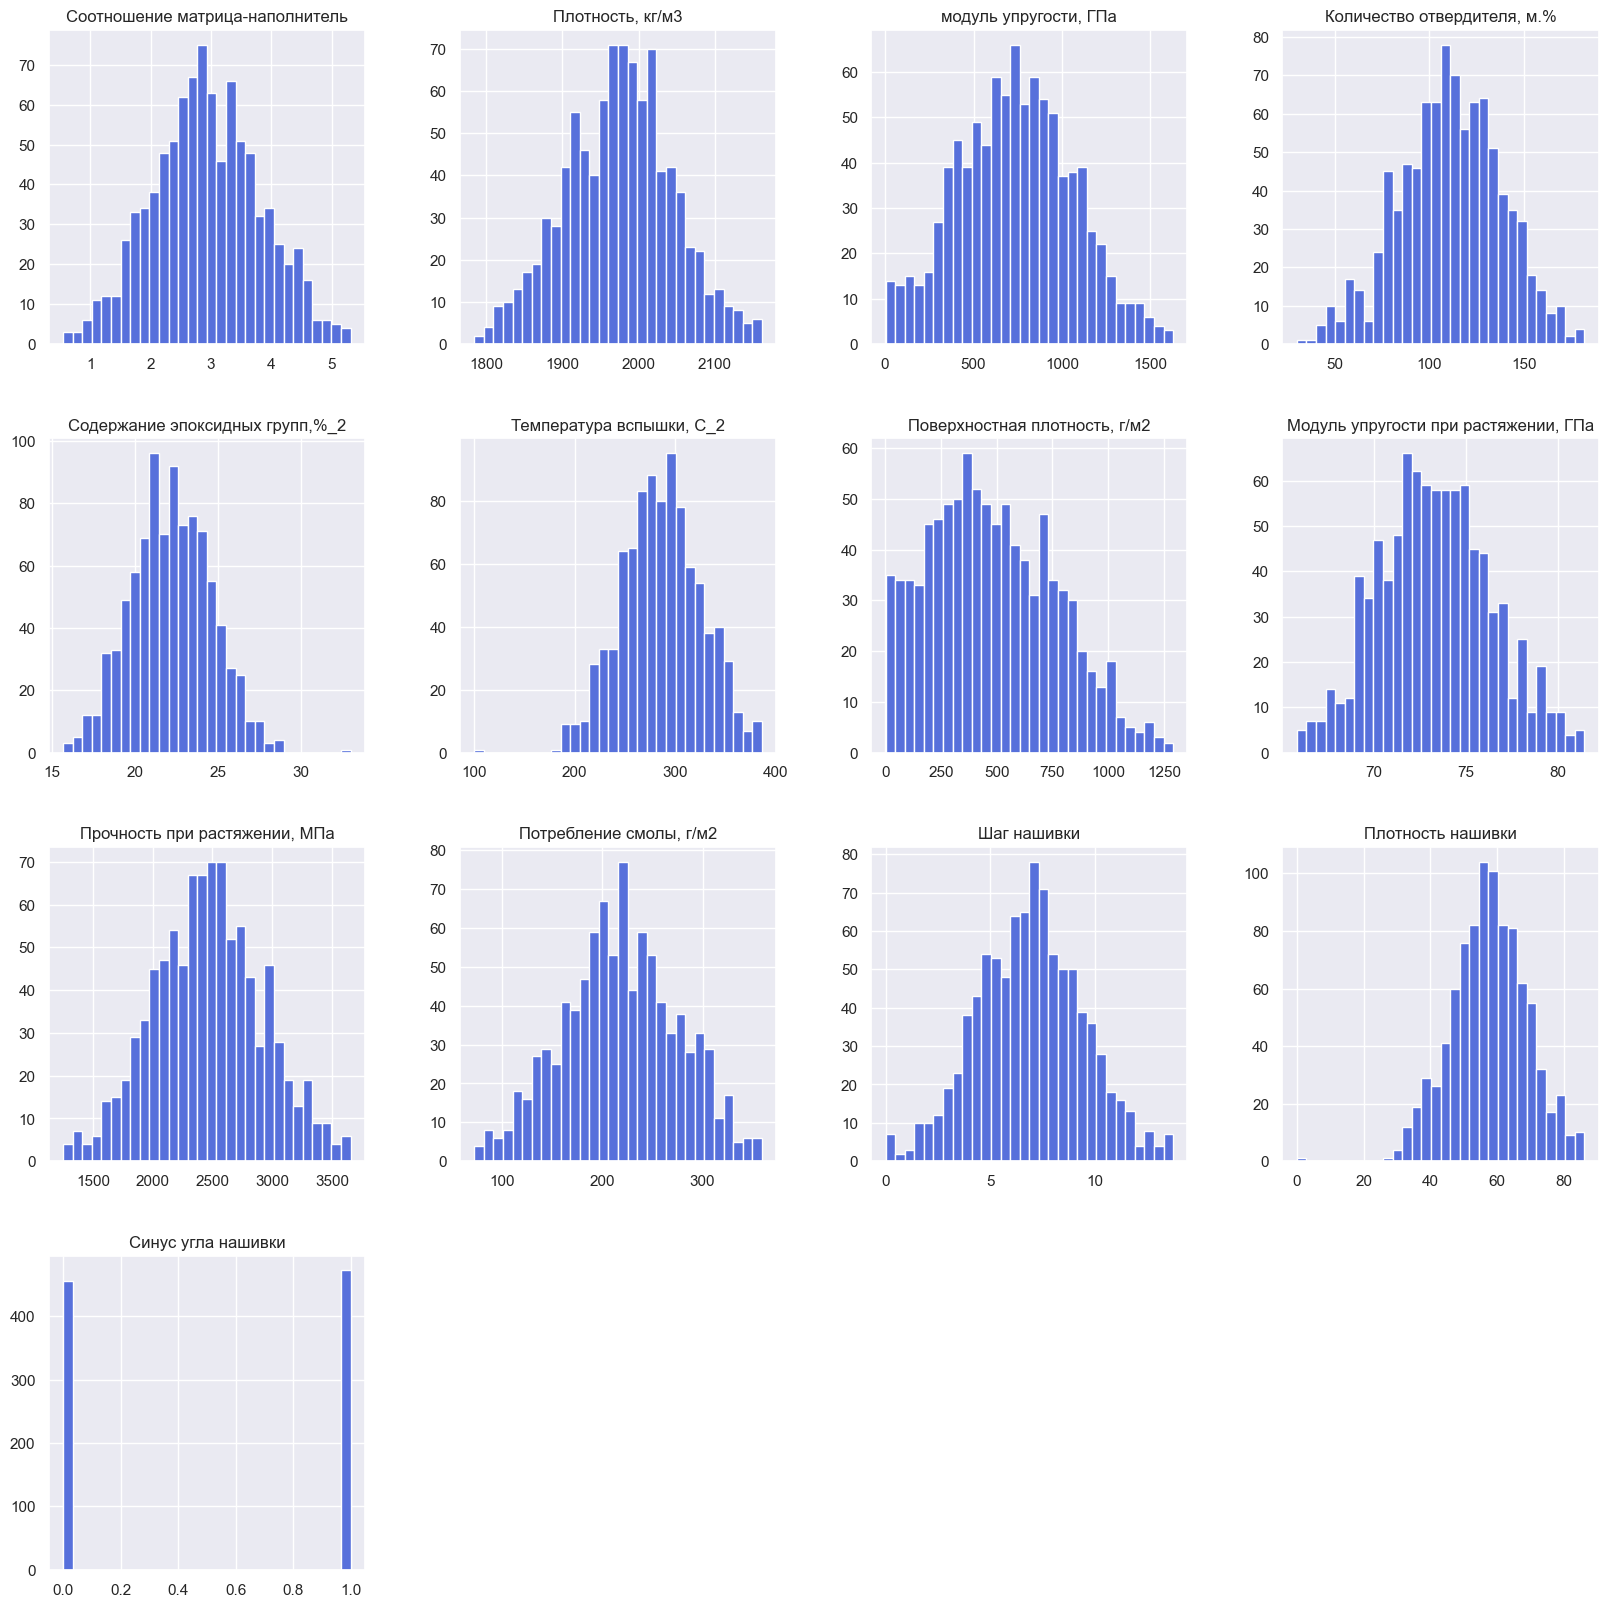

In [49]:
#Выведем распределение значений каждой переменной 

sns.set_style ('darkgrid')
CM_clean.hist(bins = 30, figsize=(20, 20), color=selected_palette[5])
plt.show()

## Подготовка данных для обучения

In [15]:
#Разделим данные на наборы для модели №1, которая будет работать
#с целевыми переменными

y1 = CM_clean[['Модуль упругости при растяжении, ГПа','Прочность при растяжении, МПа']].copy()         #целевая переменная
X1 = CM_clean.drop(['Модуль упругости при растяжении, ГПа','Прочность при растяжении, МПа'], axis=1)   #признаки

In [53]:
X1

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Потребление смолы, г/м2",Шаг нашивки,Плотность нашивки,Cинус угла нашивки
0,1.857143,2030.000000,738.736842,30.000000,22.267857,100.000000,210.000000,220.000000,4.000000,57.000000,0.0
1,1.857143,2030.000000,738.736842,50.000000,23.750000,284.615385,210.000000,220.000000,4.000000,60.000000,0.0
2,1.857143,2030.000000,738.736842,49.900000,33.000000,284.615385,210.000000,220.000000,4.000000,70.000000,0.0
3,1.857143,2030.000000,738.736842,129.000000,21.250000,300.000000,210.000000,220.000000,5.000000,47.000000,0.0
4,2.771331,2030.000000,753.000000,111.860000,22.267857,284.615385,210.000000,220.000000,5.000000,57.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...
922,2.271346,1952.087902,912.855545,86.992183,20.123249,324.774576,209.198700,125.007669,9.076380,47.019770,1.0
923,3.444022,2050.089171,444.732634,145.981978,19.599769,254.215401,350.660830,117.730099,10.565614,53.750790,1.0
924,3.280604,1972.372865,416.836524,110.533477,23.957502,248.423047,740.142791,236.606764,4.161154,67.629684,1.0
925,3.705351,2066.799773,741.475517,141.397963,19.246945,275.779840,641.468152,197.126067,6.313201,58.261074,1.0


In [55]:
X1.describe()

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Потребление смолы, г/м2",Шаг нашивки,Плотность нашивки,Cинус угла нашивки
count,927.000000,927.000000,927.000000,927.000000,927.000000,927.000000,927.000000,927.000000,927.000000,927.000000,927.000000
mean,2.926259,1974.265138,737.232638,110.925330,22.214377,285.983776,482.290178,218.189164,6.919988,57.520304,0.509169
std,0.894656,70.931687,327.326279,26.953334,2.416230,39.812690,280.531530,57.203916,2.521710,11.260739,0.500186
min,0.547391,1784.482245,2.436909,30.000000,15.695894,100.000000,0.603740,72.530873,0.000000,0.000000,0.000000
25%,2.319244,1923.536424,500.047452,92.620105,20.567437,259.170041,264.063336,179.891771,5.133650,50.277138,0.000000
50%,2.906878,1977.562320,738.736842,111.157879,22.178914,286.093012,456.908047,219.179155,6.968698,57.603262,1.000000
75%,3.546885,2020.369531,957.386959,129.884490,23.959367,313.002106,695.217842,256.760915,8.607812,64.826860,1.000000
max,5.314144,2161.565216,1628.000000,181.828448,33.000000,386.067992,1291.340115,359.052220,13.732404,86.012427,1.000000


In [57]:
y1

,"Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа"
0,70.000000,3000.000000
1,70.000000,3000.000000
2,70.000000,3000.000000
3,70.000000,3000.000000
4,70.000000,3000.000000
...,...,...
922,73.090961,2387.292495
923,72.920827,2360.392784
924,74.734344,2662.906040
925,74.042708,2071.715856


In [59]:
y1.describe()

,"Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа"
count,927.000000,927.000000
mean,73.310605,2462.489797
std,3.037274,455.907695
min,65.793845,1250.392802
25%,71.229278,2146.295983
50%,73.253725,2456.393368
75%,75.311290,2751.668715
max,81.417126,3656.158363


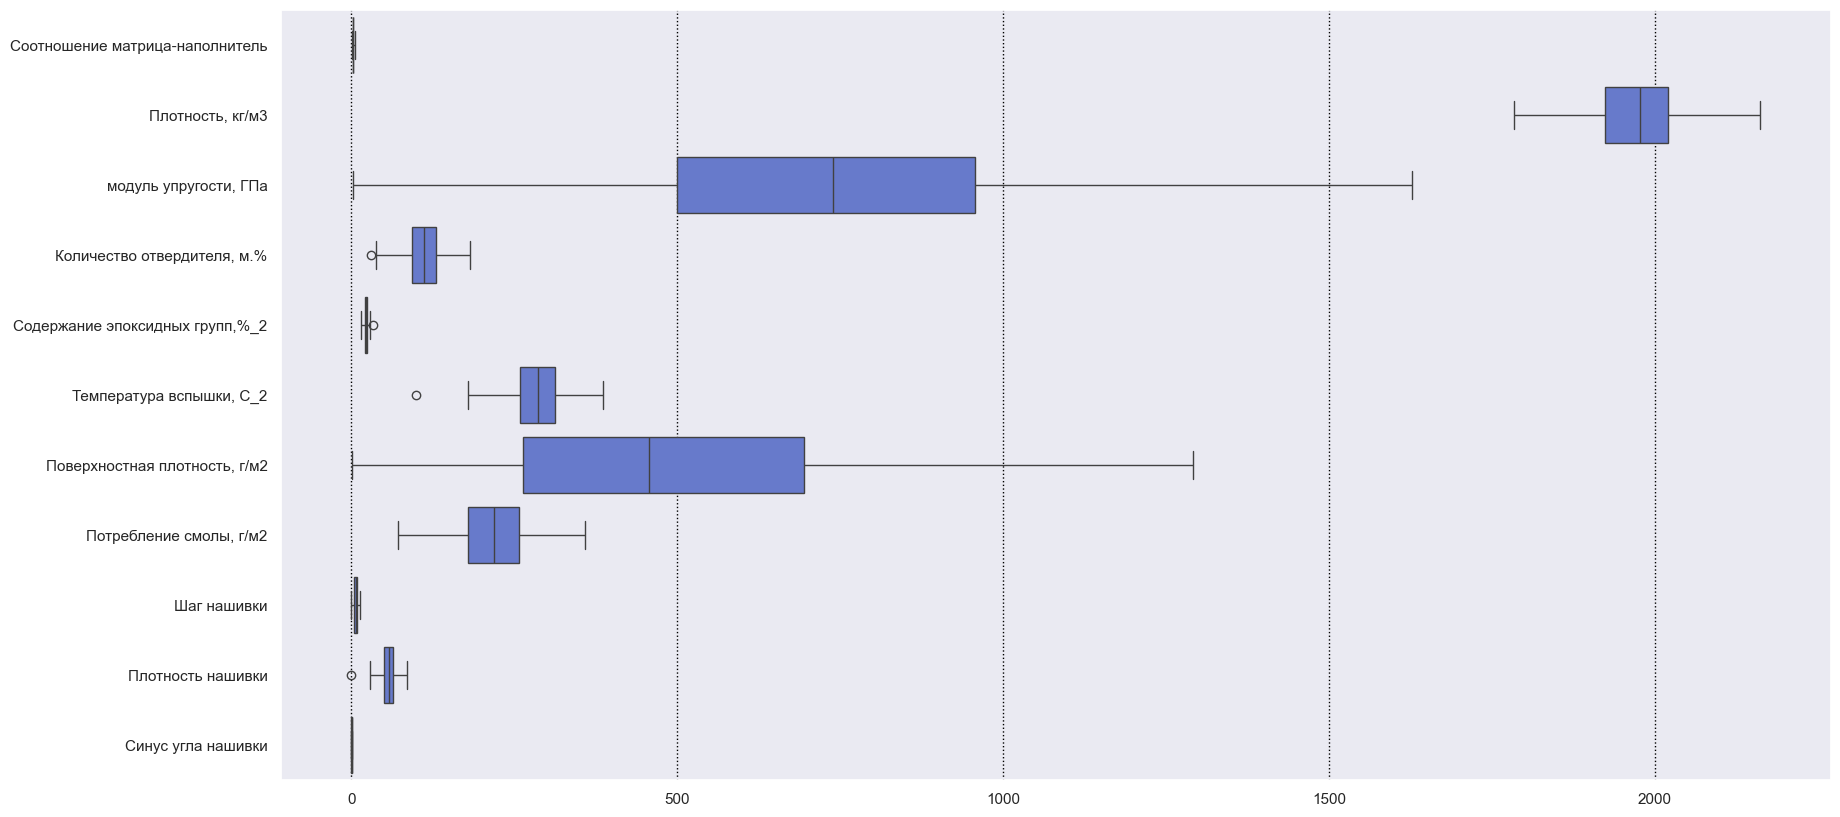

In [61]:

plt.figure(figsize=(20,10))
sns.set_style("darkgrid", {"grid.color":"0", "grid.linestyle":":"})
sns.boxplot(data = X1, color=selected_palette[5], orient='h')
plt.show()

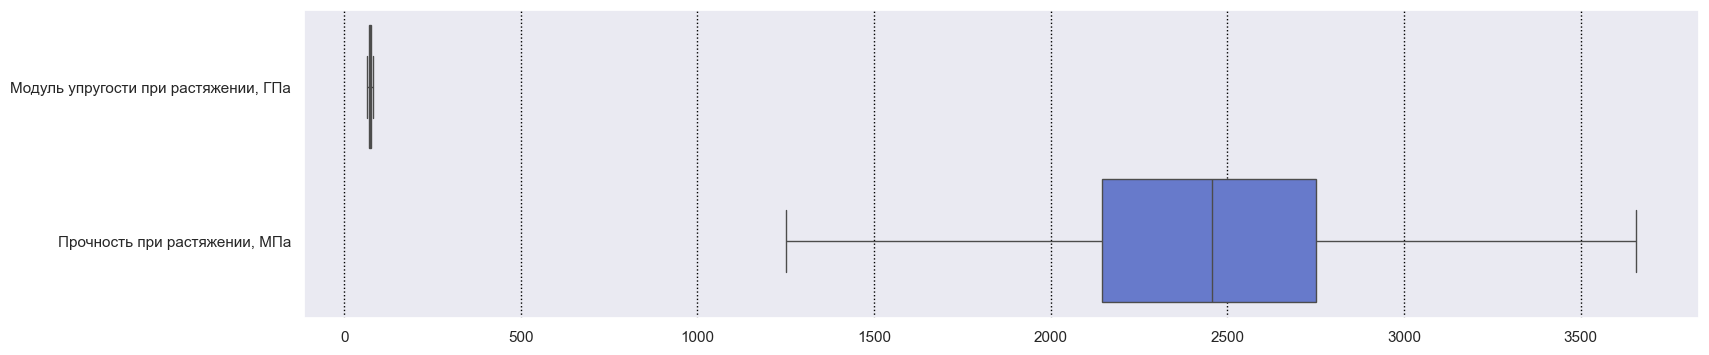

In [63]:

plt.figure(figsize=(18,4))
sns.set_style("darkgrid", {"grid.color":"0", "grid.linestyle":":"})
sns.boxplot(data = y1, color=selected_palette[5], orient='h')
plt.show()

In [29]:
# Добавим полиномиальные признаки
# poly = PolynomialFeatures(degree=2, interaction_only=False, include_bias=False)
# X1_poly_values = poly.fit_transform(X1)

# poly_feature_names = poly.get_feature_names_out(input_features=X1.columns)
# X1_poly = pd.DataFrame(X1_poly_values, columns=poly_feature_names, index=X1.index)

# print(f"Было признаков: {X1.shape[1]}")
# print(f"Стало признаков: {X1_poly.shape[1]}")

Было признаков: 11
Стало признаков: 77


In [31]:
# X1_poly.head(2)

,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Потребление смолы, г/м2",Шаг нашивки,Плотность нашивки,...,"Потребление смолы, г/м2^2","Потребление смолы, г/м2 Шаг нашивки","Потребление смолы, г/м2 Плотность нашивки","Потребление смолы, г/м2 Cинус угла нашивки",Шаг нашивки^2,Шаг нашивки Плотность нашивки,Шаг нашивки Cинус угла нашивки,Плотность нашивки^2,Плотность нашивки Cинус угла нашивки,Cинус угла нашивки^2
0,1.857143,2030.0,738.736842,30.0,22.267857,100.000000,210.0,220.0,4.0,57.0,...,48400.0,880.0,12540.0,0.0,16.0,228.0,0.0,3249.0,0.0,0.0
1,1.857143,2030.0,738.736842,50.0,23.750000,284.615385,210.0,220.0,4.0,60.0,...,48400.0,880.0,13200.0,0.0,16.0,240.0,0.0,3600.0,0.0,0.0


In [17]:
# Разделим реальные и синтетические данные

X1_real = X1.iloc[:23].values
y1_real = y1.iloc[:23].values
X1_aug = X1.iloc[23:].values
y1_aug = y1.iloc[23:].values

In [19]:

loo = LeaveOneOut()

targets = ['Модуль упругости при растяжении, ГПа', 'Прочность при растяжении, МПа']

y_true_loo = {t: [] for t in targets}
y_pred_loo = {t: [] for t in targets}

# Формируем train: реальные (без одной) + синтетика
for fold, (train_idx, test_idx) in enumerate(loo.split(X1_real)):
    try:
        X_tr = np.vstack([X1_real[train_idx], X1_aug])
        y_tr = pd.DataFrame(
            np.vstack([y1_real[train_idx], y1_aug]),
            columns=targets
        )
        X_te = X1_real[test_idx]
        y_te = y1_real[test_idx]

        hard_idx = {7, 8, 17, 18}
        real_weights = [
                        200 if idx in hard_idx else 50
                        for idx in train_idx
                        ]
        sample_weights = np.array(real_weights + [1] * len(X1_aug))

        scaler = RobustScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_te_s = scaler.transform(X_te)

        model_loo = RandomForestRegressor(
            n_estimators=250,
            max_depth=None,
            min_samples_split=20,
            min_samples_leaf=4,
            max_features=0.5,
            random_state=5,
            bootstrap=True,
            n_jobs=-1
        )
        model_loo.fit(X_tr_s, y_tr, sample_weight=sample_weights)
        y_pred = model_loo.predict(X_te_s)

        for i, t in enumerate(targets):
            y_true_loo[t].append(float(y_te[0, i]))
            y_pred_loo[t].append(float(y_pred[0, i]))

    except Exception as e:
        print(f"  Ошибка на fold {fold}: {type(e).__name__}: {e}")
        break

print(f"\nИтого итераций: {len(y_true_loo[targets[0]])}")




Итого итераций: 23


In [35]:
#Делим данные на тренировочные (train), валидационные (val) и тестовые (test) выборки реальные данные
#Для получения валидационной выборки делим тестовую выборку пополам

# X1_real_train, X1_real_test_full, y1_real_train, y1_real_test_full = train_test_split(X1_real, y1_real, test_size=0.4, shuffle=True, random_state=5)
# X1_real_test, X1_real_val, y1_real_test, y1_real_val = train_test_split(X1_real_test_full, y1_real_test_full, test_size=0.5, shuffle=True, random_state=5)

In [47]:
# #Формируем финальные выборки
# #В тренировочную выборку добавляем синтетические данные для стабильности обучения

# X1_train_vs = np.vstack([X1_real_train, X1_aug])
# y1_train_vs = np.vstack([y1_real_train, y1_aug])


# X1_val = X1_real_val
# y1_val = y1_real_val

# X1_test = X1_real_test
# y1_test = y1_real_test

In [39]:
# # Проверим размеры полученных наборов

# print(f"Размеры выборок целевой переменной:")
# print(f"Полная: {len(y1)}, Train: {len(y1_train)}, Test: {len(y1_test)}, Val: {len(y1_val)}")
# print(f"\nРазмеры выборок признаков:")
# print(f"Полная: {len(X1)}, Train: {len(X1_train)}, Test: {len(X1_test)}, Val: {len(X1_val)}")

Размеры выборок целевой переменной:
Полная: 927, Train: 920, Test: 3, Val: 4

Размеры выборок признаков:
Полная: 927, Train: 920, Test: 3, Val: 4


In [49]:
# Рассмотрим распределение признаков в полученных выборках
# targets = ['Модуль упругости при растяжении, ГПа', 'Прочность при растяжении, МПа']

# y1_train = pd.DataFrame(
#     np.vstack([y1_real_train, y1_aug]),
#     columns=targets
# )


# for target in ['Модуль упругости при растяжении, ГПа', 'Прочность при растяжении, МПа']:
#     print(f"\n{target}:")
#     print(f"  Train: mean={y1_train[target].mean():.2f}, std={y1_train[target].std():.2f}")
#     print(f"  Val:   mean={y1_val[target].mean():.2f}, std={y1_val[target].std():.2f}")
#     print(f"  Test:  mean={y1_test[target].mean():.2f}, std={y1_test[target].std():.2f}")



Модуль упругости при растяжении, ГПа:
  Train: mean=73.30, std=3.04
  Val:   mean=74.08, std=3.34
  Test:  mean=75.44, std=2.36

Прочность при растяжении, МПа:
  Train: mean=2464.37, std=455.74
  Val:   mean=2313.89, std=533.36
  Test:  mean=2085.19, std=335.98


In [23]:
# Выполним масштабирование признаков
#scaler_X = RobustScaler()

# X1_train_scaled = scaler_X.fit_transform(X1_train)
# X1_val_scaled = scaler_X.transform(X1_val)
# X1_test_scaled = scaler_X.transform(X1_test)



In [21]:

X_full = np.vstack([X1_real, X1_aug])
y_full = pd.DataFrame(
                    np.vstack([y1_real, y1_aug]),
                    columns=targets
                    )

hard_idx = {7, 8, 17, 18}
real_weights = [
    200 if idx in hard_idx else 50
    for idx in range(len(X1_real))
]
sw_full = np.array(real_weights + [1] * len(X1_aug))

scaler_final = RobustScaler()
X_full_s = scaler_final.fit_transform(X_full)

In [23]:
# Возьмем модель RandomForestRegressor в качестве BaseLine
# Для присвоим веса реальным и синтетическим данным
# Чтобы реальные имели больший вес при обучении

# n_real_train = len(X1_real_train)
# n_aug_train  = len(X1_aug)
# sample_weights = np.array([50] * n_real_train + [1] * n_aug_train)


baseline = RandomForestRegressor(
    n_estimators=250,
    max_depth=None,
    min_samples_split=20,
    min_samples_leaf=4,
    max_features=0.5,
    random_state=5,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    verbose=0
)

baseline.fit(X_full_s, y_full, sample_weight=sw_full)

# y1_pred_test = baseline.predict(X1_test_scaled)
# y1_pred_train = baseline.predict(X1_train_scaled)
# y1_pred_val = baseline.predict(X1_val_scaled)

print(f"\nOOB score: {baseline.oob_score_:.4f}")

#targets = ['Модуль упругости при растяжении, ГПа', 'Прочность при растяжении, МПа']

print(f"{'Целевая переменная':<45} {'R² LOO':>8} {'MAE LOO':>10}")
print("-" * 77)
for t in targets:
    yt = np.array(y_true_loo[t])
    yp = np.array(y_pred_loo[t])
    r2  = r2_score(yt, yp)
    mae = mean_absolute_error(yt, yp)
    print(f"{t:<45} {r2:>8.4f} {mae:>10.4f}")


OOB score: -0.0015
Целевая переменная                              R² LOO    MAE LOO
-----------------------------------------------------------------------------
Модуль упругости при растяжении, ГПа            0.7502     1.1814
Прочность при растяжении, МПа                   0.7818   185.5838


In [25]:

print(f"\n{'='*65}")
print("Детализация LOO-CV (факт vs прогноз):")
print(f"{'-'*65}")

for t in targets:
    yt = np.array(y_true_loo[t])
    yp = np.array(y_pred_loo[t])
    err = np.abs(yt - yp)
    print(f"\n{t}:")
    print(f"  {'Строка':>6}  {'Факт':>10}  {'Прогноз':>10}  {'|Ошибка|':>10}  {'%':>6}")
    print(f"  {'-'*46}")
    for i in range(len(yt)):
        pct = err[i] / abs(yt[i]) * 100 if yt[i] != 0 else float('nan')
        print(f"  {i:>6}  {yt[i]:>10.3f}  {yp[i]:>10.3f}  {err[i]:>10.3f}  {pct:>5.1f}%")
    print(f"  {'Среднее':>6}  {yt.mean():>10.3f}  {yp.mean():>10.3f}  "
          f"{err.mean():>10.3f}  {(err/np.abs(yt)*100).mean():>5.1f}%")


Детализация LOO-CV (факт vs прогноз):
-----------------------------------------------------------------

Модуль упругости при растяжении, ГПа:
  Строка        Факт     Прогноз    |Ошибка|       %
  ----------------------------------------------
       0      70.000      70.689       0.689    1.0%
       1      70.000      70.540       0.540    0.8%
       2      70.000      70.573       0.573    0.8%
       3      70.000      70.992       0.992    1.4%
       4      70.000      70.450       0.450    0.6%
       5      70.000      70.848       0.848    1.2%
       6      70.000      71.280       1.280    1.8%
       7      75.000      73.588       1.412    1.9%
       8      75.000      73.814       1.186    1.6%
       9      78.000      75.827       2.173    2.8%
      10      78.000      75.024       2.976    3.8%
      11      78.000      75.675       2.325    3.0%
      12      73.333      73.348       0.014    0.0%
      13      73.333      73.197       0.137    0.2%
      14    

In [ ]:

explainer = shap.TreeExplainer(baseline)
shap_values = explainer.shap_values(X_full_s)

shap.summary_plot(shap_values,X_full_s)

In [ ]:
shap.summary_plot(shap_values,X_full_s, plot_type="bar")

In [ ]:
shap.dependence_plot("feature_name", shap_values, X_full_s)

In [ ]:
interaction_values = explainer.shap_interaction_values(X_full_s)
shap.summary_plot(interaction_values, X_full_s)

In [ ]:
shap.dependence_plot(
    "feature_name",
    shap_values,
    X_full_s,
    interaction_index="auto"
)

In [ ]:

sample_id = 0

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[sample_id],
        base_values=explainer.expected_value,
        data=X_full_s.iloc[sample_id],
        feature_names=X_full_s.columns
    )
)

In [ ]:

shap.initjs()

sample_id = 0

shap.force_plot(
    explainer.expected_value,
    shap_values[sample_id],
    X_full_s.iloc[sample_id]
)

In [ ]:

importance = np.abs(shap_values).mean(axis=0)

importance_df = pd.DataFrame({
    "feature": X_full_s.columns,
    "importance": importance
}).sort_values("importance", ascending=False)

print(importance_df)

## Подбор модели ML для прогнозирования переменной №1 "Модуль упругости при растяжении" ##

### Модель №1. Stochastic Gradient Descent Regressor ###

In [ ]:
# Подбор гиперпараметров модели с помощью Optuna

def objective(trial):
    sgdr1 = SGDRegressor(
        loss=trial.suggest_categorical('loss', ['squared_error', 'huber']),
        penalty=trial.suggest_categorical('penalty', ['l2', 'l1', 'elasticnet']),
        alpha=trial.suggest_float('alpha', 1e-5, 1e-1, log=True),
        l1_ratio=trial.suggest_float('l1_ratio', 0.15, 0.85),
        max_iter=trial.suggest_int('max_iter', 1000, 5000),
        epsilon=trial.suggest_float('epsilon', 0.01, 0.5),
        learning_rate=trial.suggest_categorical('learning_rate', ['optimal', 'invscaling', 'adaptive']),
        eta0=trial.suggest_float('eta0', 1e-4, 1e-1, log=True),
        random_state=42,
        tol=1e-3
    )
    
    sgdr1.fit(X_train1_scaled, y_train1)
    y_pred = sgdr1.predict(X_val1_scaled)

    mse = mean_squared_error(y_val1, y_pred)
    return mse

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='minimize')  # Минимизируем MSE
study.optimize(objective, n_trials=200, n_jobs=-1, show_progress_bar=True)

print(f"Лучший MSE: {study.best_value:.4f}")
print(f"Лучшие параметры: {study.best_params}")

#     mae_opt_sgdr = mean_absolute_error(y_val1, y_pred_opt)
#     mape_opt_sgdr = mean_absolute_percentage_error(y_val1, y_pred_opt)
#     mse_opt_sgdr = mean_squared_error(y_val1, y_pred_opt)
#     rmse_opt_sgdr = np.sqrt(mse_opt_sgdr)
#     r2_opt_sgdr = r2_score(y_val1, y_pred_opt)

#     return mae_opt_sgdr, mape_opt_sgdr, mse_opt_sgdr, rmse_opt_sgdr, r2_opt_sgdr

# optuna.logging.set_verbosity(optuna.logging.WARNING)

# study = optuna.create_study(directions=['minimize', 'minimize', 'minimize', 'minimize', 'maximize'],
#                                         study_name='SGDR_multimetrics')
# study.optimize(objective, n_trials=200, n_jobs=-1, show_progress_bar=False)

# pareto_trials = study.best_trials
# pareto_sorted = sorted(pareto_trials, key=lambda t: t.values[4], reverse=True)
# top5_pareto = pareto_sorted[:5]

# print('Лучшие варианты:')
# print('=' * 120)
# for i, t in enumerate(top5_pareto, start=1):
#     print(f'№{i} | MAE={t.values[0]:.4f}, MAPE={t.values[1]:.4f}, MSE={t.values[2]:.4f}, RMSE={t.values[3]:.4f}, R2={t.values[4]:.4f}')
#     print('Параметры:', t.params)
#     print('-' * 120)
# print('=' * 120)

  0%|          | 0/200 [00:00<?, ?it/s]

In [43]:
# Поиск лучших гиперпараметров байесовкским методом (BayesSearchCV)
# Сюда вносим гиперпараметры от вариантов моделей, выбраных Optuna

param_dict_sgdr1 = {'loss': Categorical(['huber', 'epsilon_insensitive']),
                    'penalty': Categorical(['l1', 'elasticnet']),
                    'alpha': Real(0.00001, 1.00),
                    'l1_ratio': Real(0.2, 0.9),
                    'max_iter': Integer(2300, 2400),
                    'epsilon': Real(2.0, 5.00),
                    'learning_rate': Categorical(['invscaling', 'adaptive']),
                    'eta0': Real(0.0001, 0.4)}

bs_search = BayesSearchCV(SGDRegressor(), param_dict_sgdr1, optimizer_kwargs={'base_estimator': 'GP'}, scoring='r2',
                          n_iter=50, n_jobs=-1, cv=10, verbose=0, random_state=42)
bs_search.fit(X_train1, y_train1)

best_parameter = bs_search.best_params_ 
best_scoring = bs_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Лучшие параметры: OrderedDict([('alpha', 1.0), ('epsilon', 5.0), ('eta0', 0.4), ('l1_ratio', 0.2), ('learning_rate', 'adaptive'), ('loss', 'epsilon_insensitive'), ('max_iter', 2300), ('penalty', 'elasticnet')])
Лучшая оценка: -0.23657849242481782


In [73]:
# Проведем валидацию полученнной модели с лучшими гиперпараметрами

sgdr1_best = SGDRegressor(loss='epsilon_insensitive', penalty='l1', alpha=0.0108, l1_ratio=0.0409, max_iter=1539, 
                          shuffle=True, epsilon=0.0148, random_state=42, learning_rate='invscaling', eta0=0.017785)

val_sgdr1 = cross_val_score(sgdr1_best, X_val1, y_val1, cv=10, n_jobs=-1, scoring='r2')
val_sgdr1

array([0.92766946, 0.89624881, 0.90491226, 0.82817554, 0.85345195,
       0.83558377, 0.89900047, 0.87080809, 0.87394384, 0.89034727])

In [75]:
# Cовместим тренировочный и валидационный наборы, затем проведем повторное обучение модели на совмещенных данных

X_train_final = np.concatenate([X_train1, X_val1])
y_train_final = np.concatenate([y_train1, y_val1])

sgdr1_best.fit(X_train_final, y_train_final)
print(f'Лучшая оценка: {sgdr1_best.score(X_train_final, y_train_final)}')

Лучшая оценка: 0.8973934598129689


In [77]:
# Проведем финальную проверку модели с помощью предсказания на тестовых данных

y_pred_sgdr1 = sgdr1_best.predict(X_test1)

In [79]:
# Получим оценки на тестовой выборке

mae_sgdr1 = mean_absolute_error(y_pred_sgdr1, y_test1)
mape_sgdr1 = mean_absolute_percentage_error(y_pred_sgdr1, y_test1)
mse_sgdr1 = mean_squared_error(y_pred_sgdr1, y_test1)
rmse_sgdr1 = np.sqrt(mse_sgdr1)
r2_sgdr1 = sgdr1_best.score(X_test1, y_test1)

print('Оценки для SGDRegressor:')
print('Оценка MAE: {:.3f}'.format(mae_sgdr1))
print('Оценка MAPE: {:.3f}'.format(mape_sgdr1))
print('Оценка MSE: {:.3f}'.format(mse_sgdr1))
print('Оценка RMSE: {:.3f}'.format (rmse_sgdr1))
print('Оценка R2: {:.3f}'.format(r2_sgdr1))

Оценки для SGDRegressor:
Оценка MAE: 0.271
Оценка MAPE: 1.351
Оценка MSE: 0.116
Оценка RMSE: 0.341
Оценка R2: 0.879


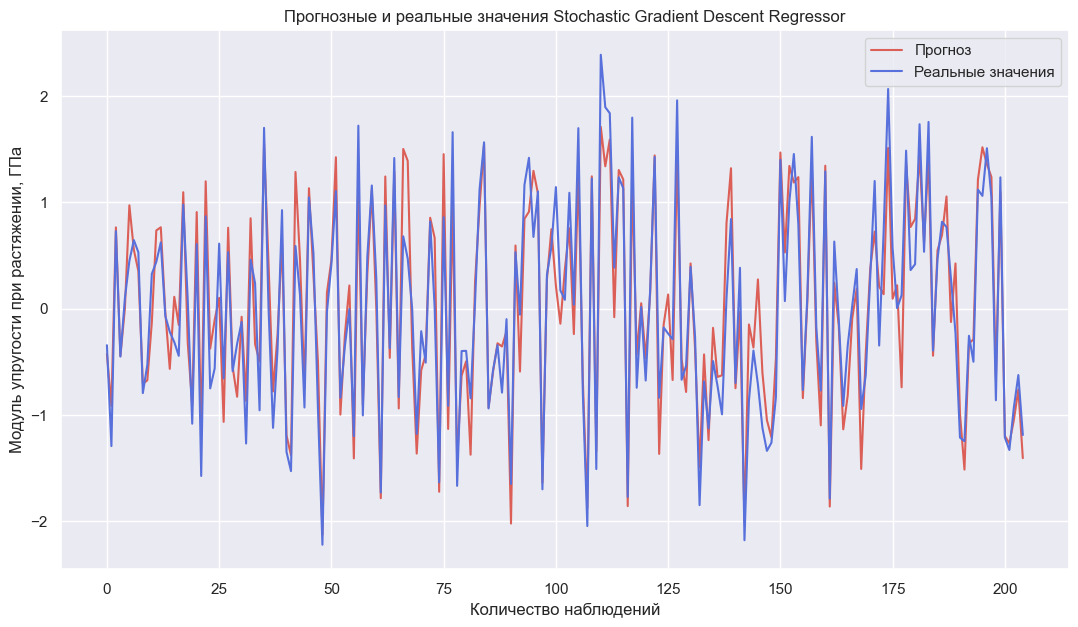

In [81]:
#Cопоставим прогнозные и реальные значения на совмещенном графике

plt.figure(figsize = (13, 7))
plt.title("Прогнозные и реальные значения Stochastic Gradient Descent Regressor")
plt.plot(y_pred_sgdr1, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test1.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Модуль упругости при растяжении, ГПа")
plt.legend()
plt.grid(True);

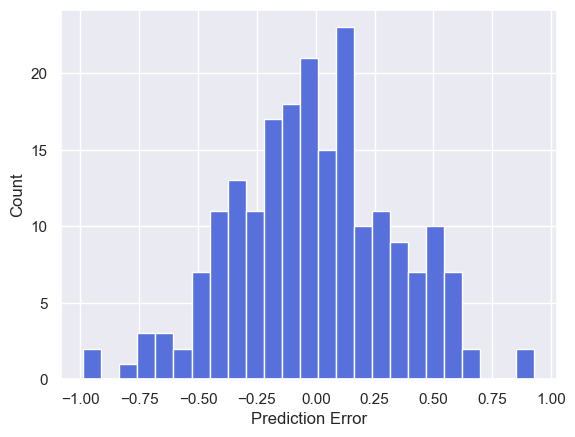

In [83]:
#Визуализация гистограммы распределения ошибки

error = y_test1 - y_pred_sgdr1
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
_ = plt.ylabel('Count')

### Модель №2. Support Vector Regression ###

In [85]:
# Подбор гиперпараметров модели с помощью Optuna

def objective(trial):
    param_distrib_svr1 = {'kernel': trial.suggest_categorical('kernel', ['linear', 'poly', 'rbf']),
                          'С': trial.suggest_float('C', 0.0, 500.0),
                          'gamma': trial.suggest_categorical('gamma', ['scale', 'auto']),
                          'epsilon': trial.suggest_float('epsilon', 1e-4, 1e+1, log=True),
                          'degree': trial.suggest_int('degree', 1, 5)}

    svr1 = SVR()
    svr1.fit(X_train1, y_train1)

    y_pred_opt = svr1.predict(X_val1)

    mae_opt_svr = mean_absolute_error(y_val1, y_pred_opt)
    mape_opt_svr = mean_absolute_percentage_error(y_val1, y_pred_opt)
    mse_opt_svr = mean_squared_error(y_val1, y_pred_opt)
    rmse_opt_svr = np.sqrt(mse_opt_svr)
    r2_opt_svr = r2_score(y_val1, y_pred_opt)

    return mae_opt_svr, mape_opt_svr, mse_opt_svr, rmse_opt_svr, r2_opt_svr

optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(directions=['minimize', 'minimize', 'minimize', 'minimize', 'maximize'],
                                        study_name='SVR_multimetrics')
study.optimize(objective, n_trials=200, n_jobs=-1, show_progress_bar=False)

pareto_trials = study.best_trials
pareto_sorted = sorted(pareto_trials, key=lambda t: t.values[4], reverse=True)
top5_pareto = pareto_sorted[:3]

print('Лучшие варианты:')
print('=' * 120)
for i, t in enumerate(top5_pareto, start=1):
    print(f'№{i} | MAE={t.values[0]:.4f}, MAPE={t.values[1]:.4f}, MSE={t.values[2]:.4f}, RMSE={t.values[3]:.4f}, R2={t.values[4]:.4f}')
    print('Параметры:', t.params)
    print('-' * 120)
print('=' * 120)

Лучшие варианты:
№1 | MAE=0.2887, MAPE=1.0695, MSE=0.1283, RMSE=0.3582, R2=0.8723
Параметры: {'kernel': 'linear', 'C': 412.3387971670374, 'gamma': 'scale', 'epsilon': 0.33561108871995504, 'degree': 2}
------------------------------------------------------------------------------------------------------------------------
№2 | MAE=0.2887, MAPE=1.0695, MSE=0.1283, RMSE=0.3582, R2=0.8723
Параметры: {'kernel': 'poly', 'C': 339.80944629676577, 'gamma': 'auto', 'epsilon': 3.4348278729242576, 'degree': 4}
------------------------------------------------------------------------------------------------------------------------
№3 | MAE=0.2887, MAPE=1.0695, MSE=0.1283, RMSE=0.3582, R2=0.8723
Параметры: {'kernel': 'rbf', 'C': 106.17585286673409, 'gamma': 'auto', 'epsilon': 0.15019771628994044, 'degree': 1}
------------------------------------------------------------------------------------------------------------------------


In [87]:
# Поиск лучших гиперпараметров байесовкским методом (BayesSearchCV)
# Сюда вносим гиперпараметры от вариантов моделей, выбраных Optuna

param_dict_svr1 = {'kernel': Categorical(['rbf', 'linear', 'poly']),
                    'C': Real(100, 500),
                    'gamma': Categorical(['scale', 'auto']),
                    'epsilon': Real(0.1, 4),
                    'degree': Integer(1, 4)}

bs_search = BayesSearchCV(SVR(), param_dict_svr1, optimizer_kwargs={'base_estimator': 'GP'}, scoring='r2',
                          n_iter=50, n_jobs=-1, cv=10, verbose=0, random_state=42)
bs_search.fit(X_train1, y_train1)

best_parameter = bs_search.best_params_
best_scoring = bs_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Лучшие параметры: OrderedDict([('C', 500.0), ('degree', 1), ('epsilon', 0.17828661127405834), ('gamma', 'scale'), ('kernel', 'linear')])
Лучшая оценка: 0.890499904106418


In [89]:
# Проведем валидацию полученнной модели с лучшими гиперпараметрами

svr1_best = SVR(kernel='linear', gamma='scale', C=500, epsilon=0.178, degree=1, shrinking=True)

val_svr1 = cross_val_score(svr1_best, X_val1, y_val1, cv=10, n_jobs=-1, scoring='r2')
val_svr1

array([0.90912587, 0.9002049 , 0.89044714, 0.82407555, 0.87690555,
       0.84104454, 0.88461672, 0.84884779, 0.85036852, 0.8734167 ])

In [91]:
# Cовместим тренировочный и валидационный наборы, затем проведем повторное обучение модели на совмещенных данных

X_train_final = np.concatenate([X_train1, X_val1])
y_train_final = np.concatenate([y_train1, y_val1])

svr1_best.fit(X_train_final, y_train_final)
print(f'Лучшая оценка: {svr1_best.score(X_train_final, y_train_final)}')

Лучшая оценка: 0.8985812445729123


In [93]:
# Проведем финальную проверку модели с помощью предсказания на тестовых данных

y_pred_svr1 = svr1_best.predict(X_test1)

In [95]:
# Получим оценки на тестовой выборке

mae_svr1 = mean_absolute_error(y_pred_svr1, y_test1)
mape_svr1 = mean_absolute_percentage_error(y_pred_svr1, y_test1)
mse_svr1 = mean_squared_error(y_pred_svr1, y_test1)
rmse_svr1 = np.sqrt(mse_svr1)
r2_svr1 = svr1_best.score(X_test1, y_test1)

print('Оценки для SVRegression:')
print('Оценка MAE: {:.3f}'.format(mae_svr1))
print('Оценка MAPE: {:.3f}'.format(mape_svr1))
print('Оценка MSE: {:.3f}'.format(mse_svr1))
print('Оценка RMSE: {:.3f}'.format (rmse_svr1))
print('Оценка R2: {:.3f}'.format(r2_svr1))

Оценки для SVRegression:
Оценка MAE: 0.272
Оценка MAPE: 1.031
Оценка MSE: 0.115
Оценка RMSE: 0.339
Оценка R2: 0.881


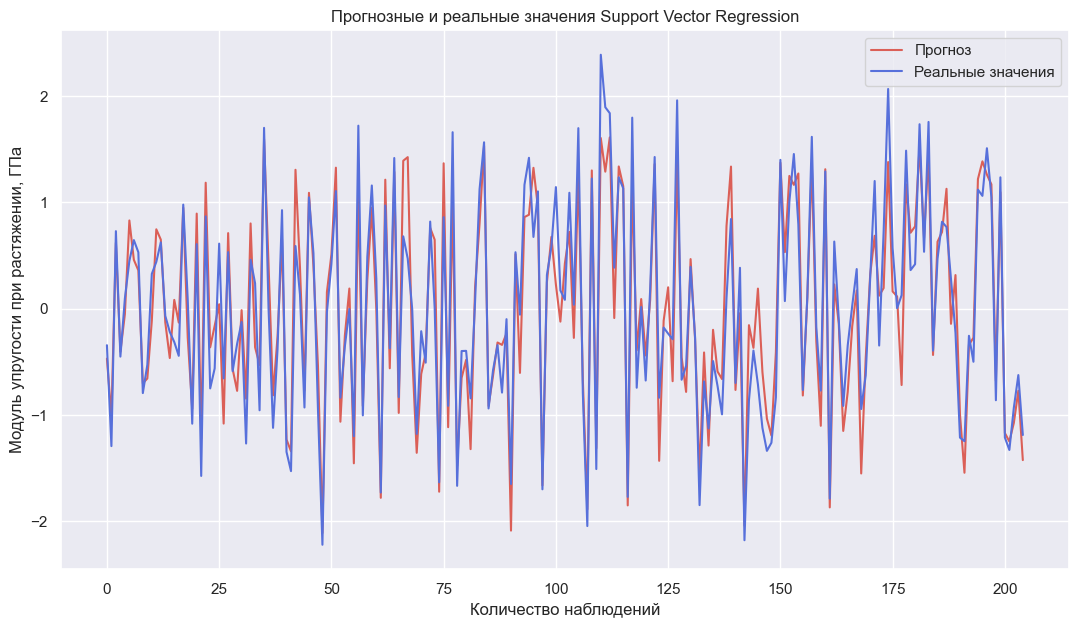

In [97]:
#Cопоставим прогнозные и реальные значения на совмещенном графике

plt.figure(figsize = (13, 7))
plt.title("Прогнозные и реальные значения Support Vector Regression")
plt.plot(y_pred_svr1, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test1.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Модуль упругости при растяжении, ГПа")
plt.legend()
plt.grid(True);

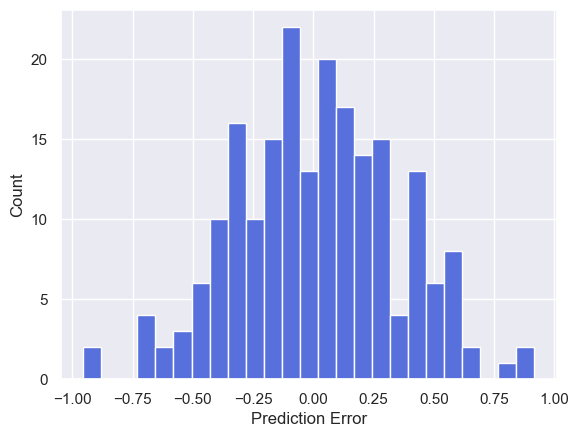

In [99]:
#Визуализация гистограммы распределения ошибки

error = y_test1 - y_pred_svr1
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
_ = plt.ylabel('Count')

### Модель №3. Gradient Boosting Regressor ###

In [101]:
# Подбор гиперпараметров модели с помощью Optuna

def objective(trial):
    param_distrib_gbr1 = {'n_estimators': trial.suggest_int('n_estimators', 10, 3000),
                          'learning_rate': trial.suggest_float('learning_rate', 1e-3, 1e+0, log=True),
                          'max_depth': trial.suggest_int('max_depth', 1, 10),
                          'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
                          'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
                          'subsample': trial.suggest_float('subsample', 1e-1, 1e+0, log=True),
                          'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None])}

    gbr1 = GradientBoostingRegressor(random_state=42)
    gbr1.fit(X_train1, y_train1)

    y_pred_opt = gbr1.predict(X_val1)

    mae_opt_gbr = mean_absolute_error(y_val1, y_pred_opt)
    mape_opt_gbr = mean_absolute_percentage_error(y_val1, y_pred_opt)
    mse_opt_gbr = mean_squared_error(y_val1, y_pred_opt)
    rmse_opt_gbr = np.sqrt(mse_opt_gbr)
    r2_opt_gbr = r2_score(y_val1, y_pred_opt)

    return mae_opt_gbr, mape_opt_gbr, mse_opt_gbr, rmse_opt_gbr, r2_opt_gbr

optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(directions=['minimize', 'minimize', 'minimize', 'minimize', 'maximize'],
                                        study_name='GBR_multimetrics')
study.optimize(objective, n_trials=200, n_jobs=-1, show_progress_bar=False)

pareto_trials = study.best_trials
pareto_sorted = sorted(pareto_trials, key=lambda t: t.values[4], reverse=True)
top5_pareto = pareto_sorted[:3]

print('Лучшие варианты:')
print('=' * 120)
for i, t in enumerate(top5_pareto, start=1):
    print(f'№{i} | MAE={t.values[0]:.4f}, MAPE={t.values[1]:.4f}, MSE={t.values[2]:.4f}, RMSE={t.values[3]:.4f}, R2={t.values[4]:.4f}')
    print('Параметры:', t.params)
    print('-' * 120)
print('=' * 120)

Лучшие варианты:
№1 | MAE=0.2644, MAPE=1.0248, MSE=0.1078, RMSE=0.3284, R2=0.8926
Параметры: {'n_estimators': 129, 'learning_rate': 0.11223732794922515, 'max_depth': 10, 'min_samples_split': 2, 'min_samples_leaf': 5, 'subsample': 0.21772554976758451, 'max_features': 'sqrt'}
------------------------------------------------------------------------------------------------------------------------
№2 | MAE=0.2644, MAPE=1.0248, MSE=0.1078, RMSE=0.3284, R2=0.8926
Параметры: {'n_estimators': 795, 'learning_rate': 0.11340476311333482, 'max_depth': 5, 'min_samples_split': 11, 'min_samples_leaf': 2, 'subsample': 0.140989851027698, 'max_features': 'log2'}
------------------------------------------------------------------------------------------------------------------------
№3 | MAE=0.2644, MAPE=1.0248, MSE=0.1078, RMSE=0.3284, R2=0.8926
Параметры: {'n_estimators': 2134, 'learning_rate': 0.8191869850247444, 'max_depth': 9, 'min_samples_split': 4, 'min_samples_leaf': 5, 'subsample': 0.1460458395807

In [103]:
# Поиск лучших гиперпараметров байесовкским методом (BayesSearchCV)
# Сюда вносим гиперпараметры от трех лучших моделей выбраных при случайном переборе

param_dict_gbr1 = {'n_estimators': Integer(100, 3000),
                   'learning_rate': Real(0.1, 0.9),
                   'max_depth': Integer(5, 10),
                   'min_samples_split': Integer(2, 11),
                   'min_samples_leaf': Integer(2, 5),
                   'subsample': Real(0.1, 0.3),
                   'max_features': Categorical(['sqrt', 'log2'])}

bs_search = BayesSearchCV(GradientBoostingRegressor(random_state=42), param_dict_gbr1, optimizer_kwargs={'base_estimator':'GBRT'},
                          scoring='r2', n_iter=50, n_jobs=-1, cv=10, verbose=0, random_state=42)
bs_search.fit(X_train1, y_train1)

best_parameter = bs_search.best_params_
best_scoring = bs_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Лучшие параметры: OrderedDict([('learning_rate', 0.10290424580379459), ('max_depth', 6), ('max_features', 'sqrt'), ('min_samples_leaf', 5), ('min_samples_split', 8), ('n_estimators', 826), ('subsample', 0.21573286724567697)])
Лучшая оценка: 0.8508463526904722


In [105]:
# Проведем валидацию полученнной модели с лучшими гиперпараметрами

gbr1_best = GradientBoostingRegressor(n_estimators=826, learning_rate=0.1029, max_depth=6, min_samples_split=8, 
                                      min_samples_leaf=5, subsample=0.2157, max_features='sqrt', random_state=42)

val_gbr1 = cross_val_score(gbr1_best, X_val1, y_val1, cv=10, n_jobs=-1, scoring='r2')
val_gbr1

array([0.86262324, 0.80471362, 0.89494526, 0.77937595, 0.85358644,
       0.80716697, 0.80292734, 0.73510314, 0.87664957, 0.84028555])

In [107]:
# Cовместим тренировочный и валидационный наборы, затем проведем повторное обучение модели на совмещенных данных

X_train_final = np.concatenate([X_train1, X_val1])
y_train_final = np.concatenate([y_train1, y_val1])

gbr1_best.fit(X_train_final, y_train_final)
print(f'Лучшая оценка: {gbr1_best.score(X_train_final, y_train_final)}')

Лучшая оценка: 0.999599556623391


In [109]:
# Проведем финальную проверку модели с помощью предсказания на тестовых данных

y_pred_gbr1 = gbr1_best.predict(X_test1)

In [111]:
# Получим оценки на тестовой выборке

mae_gbr1 = mean_absolute_error(y_pred_gbr1, y_test1)
mape_gbr1 = mean_absolute_percentage_error(y_pred_gbr1, y_test1)
mse_gbr1 = mean_squared_error(y_pred_gbr1, y_test1)
rmse_gbr1 = np.sqrt(mse_gbr1)
r2_gbr1 = gbr1_best.score(X_test1, y_test1)

print('Оценки для Gradient Boosting Regressor:')
print('Оценка MAE: {:.3f}'.format(mae_gbr1))
print('Оценка MAPE: {:.3f}'.format(mape_gbr1))
print('Оценка MSE: {:.3f}'.format(mse_gbr1))
print('Оценка RMSE: {:.3f}'.format (rmse_gbr1))
print('Оценка R2: {:.3f}'.format(r2_gbr1))

Оценки для Gradient Boosting Regressor:
Оценка MAE: 0.323
Оценка MAPE: 2.062
Оценка MSE: 0.171
Оценка RMSE: 0.413
Оценка R2: 0.823


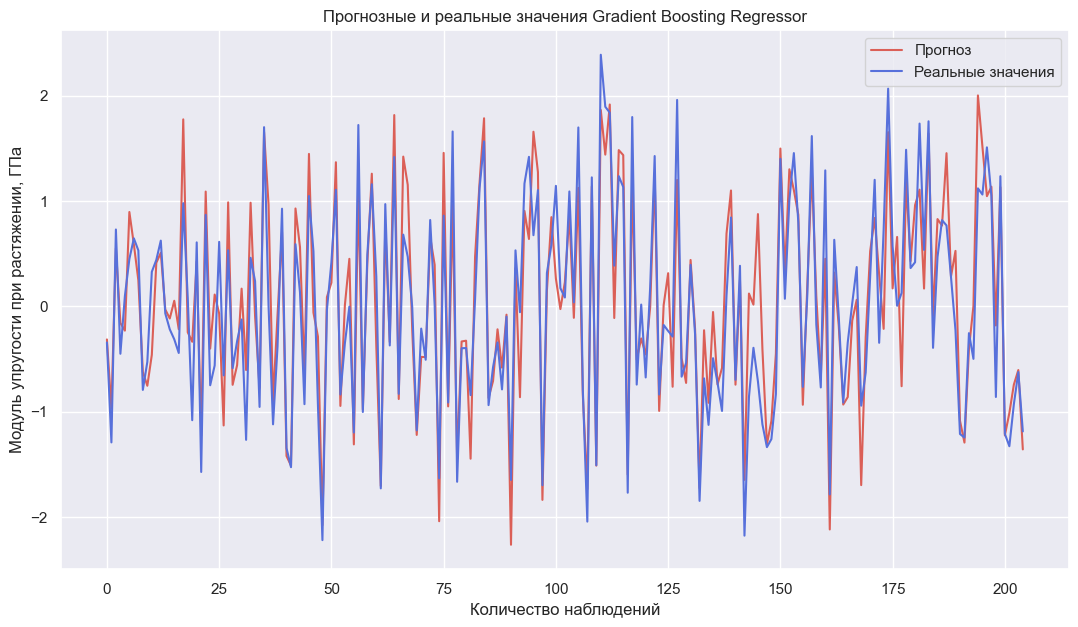

In [113]:
#Cопоставим прогнозные и реальные значения на совмещенном графике

plt.figure(figsize = (13, 7))
plt.title("Прогнозные и реальные значения Gradient Boosting Regressor")
plt.plot(y_pred_gbr1, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test1.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Модуль упругости при растяжении, ГПа")
plt.legend()
plt.grid(True);

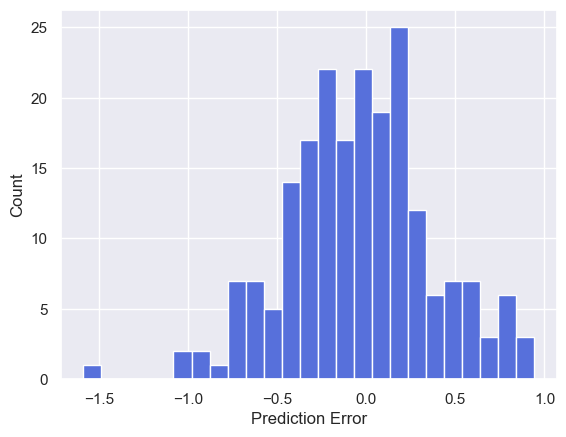

In [115]:
#Визуализация гистограммы распределения ошибки

error = y_test1 - y_pred_gbr1
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
_ = plt.ylabel('Count')

### Модель №4. eXtreme Gradient Boosting (XGBoost) Regressor ###

In [117]:
# Подбор гиперпараметров модели с помощью Optuna

def objective(trial):
    param_distrib_xgbr1 = {'booster': trial.suggest_categorical('booster', ['gbtree', 'gblinear', 'dart']),
                           'n_estimators': trial.suggest_int('n_estimators', 10, 3000),
                           'max_depth': trial.suggest_int('max_depth', 1, 10),
                           'learning_rate': trial.suggest_float('learning_rate', 1e-3, 1e+0, log=True),
                           'subsample': trial.suggest_float('subsample', 1e-1, 1e+0, log=True),
                           'colsample_bytree': trial.suggest_float('colsample_bytree', 1e-1, 1e+0, log=True),
                           'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
                           'gamma': trial.suggest_float('gamma', 0.0, 1.0),
                           'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
                           'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 1.0)}

    xgbr1 = XGBRegressor (objective='reg:squarederror', eval_metric='mae', random_state=42)
    xgbr1.fit(X_train1, y_train1)

    y_pred_opt = xgbr1.predict(X_val1)

    mae_opt_xgbr = mean_absolute_error(y_val1, y_pred_opt)
    mape_opt_xgbr = mean_absolute_percentage_error(y_val1, y_pred_opt)
    mse_opt_xgbr = mean_squared_error(y_val1, y_pred_opt)
    rmse_opt_xgbr = np.sqrt(mse_opt_xgbr)
    r2_opt_xgbr = r2_score(y_val1, y_pred_opt)

    return mae_opt_xgbr, mape_opt_xgbr, mse_opt_xgbr, rmse_opt_xgbr, r2_opt_xgbr

optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(directions=['minimize', 'minimize', 'minimize', 'minimize', 'maximize'],
                                        study_name='XGBR_multimetrics')
study.optimize(objective, n_trials=200, n_jobs=-1, show_progress_bar=False)

pareto_trials = study.best_trials
pareto_sorted = sorted(pareto_trials, key=lambda t: t.values[4], reverse=True)
top5_pareto = pareto_sorted[:3]

print('Лучшие варианты:')
print('=' * 120)
for i, t in enumerate(top5_pareto, start=1):
    print(f'№{i} | MAE={t.values[0]:.4f}, MAPE={t.values[1]:.4f}, MSE={t.values[2]:.4f}, RMSE={t.values[3]:.4f}, R2={t.values[4]:.4f}')
    print('Параметры:', t.params)
    print('-' * 120)
print('=' * 120)

Лучшие варианты:
№1 | MAE=0.2738, MAPE=0.9239, MSE=0.1137, RMSE=0.3372, R2=0.8868
Параметры: {'booster': 'gbtree', 'n_estimators': 1524, 'max_depth': 8, 'learning_rate': 0.005259424736921279, 'subsample': 0.26434864712296857, 'colsample_bytree': 0.6626080209948687, 'min_child_weight': 8, 'gamma': 0.3907445433685248, 'reg_alpha': 0.13707027274289663, 'reg_lambda': 0.8728941575798453}
------------------------------------------------------------------------------------------------------------------------
№2 | MAE=0.2738, MAPE=0.9239, MSE=0.1137, RMSE=0.3372, R2=0.8868
Параметры: {'booster': 'dart', 'n_estimators': 1269, 'max_depth': 6, 'learning_rate': 0.007366511926296106, 'subsample': 0.813862784134888, 'colsample_bytree': 0.14344608063113626, 'min_child_weight': 5, 'gamma': 0.7959158006037964, 'reg_alpha': 0.013542960688307404, 'reg_lambda': 0.39928294150402066}
------------------------------------------------------------------------------------------------------------------------
№3 |

In [121]:
# Поиск лучших гиперпараметров байесовкским методом (BayesSearchCV)
# Сюда вносим гиперпараметры от трех лучших моделей выбраных при случайном переборе

param_dict_xgbr1 = {'booster': Categorical(['gbtree', 'dart']), 
                    'n_estimators': Integer(20, 2000),
                    'max_depth': Integer(3, 8),
                    'learning_rate': Real(0.005, 0.3),
                    'subsample': Real(0.1, 0.9),
                    'colsample_bytree': Real(0.1, 0.9),
                    'min_child_weight': Integer(5, 8),
                    'gamma': Real(0.3, 1.0),
                    'reg_alpha': Real(0.01, 0.2),
                    'reg_lambda': Real(0.3, 0.9)}

bs_search = BayesSearchCV(XGBRegressor (objective='reg:squarederror', eval_metric='mae', random_state=42), param_dict_xgbr1,
                          optimizer_kwargs={'base_estimator':'GBRT'}, scoring='r2', n_iter=50, n_jobs=-1, cv=10, verbose=0, random_state=42)
bs_search.fit(X_train1, y_train1)

best_parameter = bs_search.best_params_
best_scoring = bs_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Лучшие параметры: OrderedDict([('booster', 'gbtree'), ('colsample_bytree', 0.7542640157310012), ('gamma', 0.818897921057619), ('learning_rate', 0.08009350606989324), ('max_depth', 7), ('min_child_weight', 5), ('n_estimators', 1639), ('reg_alpha', 0.1731251043784579), ('reg_lambda', 0.8471448100474237), ('subsample', 0.7004437619080428)])
Лучшая оценка: 0.8901964192609408


In [123]:
# Проведем валидацию полученнной модели с лучшими гиперпараметрами

xgbr1_best = XGBRegressor(objective='reg:squarederror', eval_metric='mae', booster='gbtree', 
                          n_estimators=1639, learning_rate=0.08009, max_depth=7, gamma=0.8188979, colsample_bytree=0.75426,
                          min_child_weight=5, subsample=0.70044, reg_alpha=0.1731, reg_lambda=0.8471, random_state=42)

val_xgbr1 = cross_val_score(xgbr1_best, X_val1, y_val1, cv=10, n_jobs=-1, scoring='r2')
val_xgbr1

array([0.9094359 , 0.90271891, 0.89808457, 0.8475577 , 0.88699729,
       0.8655728 , 0.87014953, 0.83017318, 0.8970699 , 0.89919677])

In [125]:
# Cовместим тренировочный и валидационный наборы, затем проведем повторное обучение модели на совмещенных данных

X_train_final = np.concatenate([X_train1, X_val1])
y_train_final = np.concatenate([y_train1, y_val1])

xgbr1_best.fit(X_train_final, y_train_final)
print(f'Лучшая оценка: {xgbr1_best.score(X_train_final, y_train_final)}')

Лучшая оценка: 0.9262908955414035


In [127]:
# Проведем финальную проверку модели с помощью предсказания на тестовых данных

y_pred_xgbr1 = xgbr1_best.predict(X_test1)

In [129]:
# Получим оценки на тестовой выборке

mae_xgbr1 = mean_absolute_error(y_pred_xgbr1, y_test1)
mape_xgbr1 = mean_absolute_percentage_error(y_pred_xgbr1, y_test1)
mse_xgbr1 = mean_squared_error(y_pred_xgbr1, y_test1)
rmse_xgbr1 = np.sqrt(mse_xgbr1)
r2_xgbr1 = xgbr1_best.score(X_test1, y_test1)

print('Оценки для eXtreme Gradient Boosting Regressor:')
print('Оценка MAE: {:.3f}'.format(mae_xgbr1))
print('Оценка MAPE: {:.3f}'.format(mape_xgbr1))
print('Оценка MSE: {:.3f}'.format(mse_xgbr1))
print('Оценка RMSE: {:.3f}'.format (rmse_xgbr1))
print('Оценка R2: {:.3f}'.format(r2_xgbr1))

Оценки для eXtreme Gradient Boosting Regressor:
Оценка MAE: 0.276
Оценка MAPE: 1.375
Оценка MSE: 0.115
Оценка RMSE: 0.339
Оценка R2: 0.881


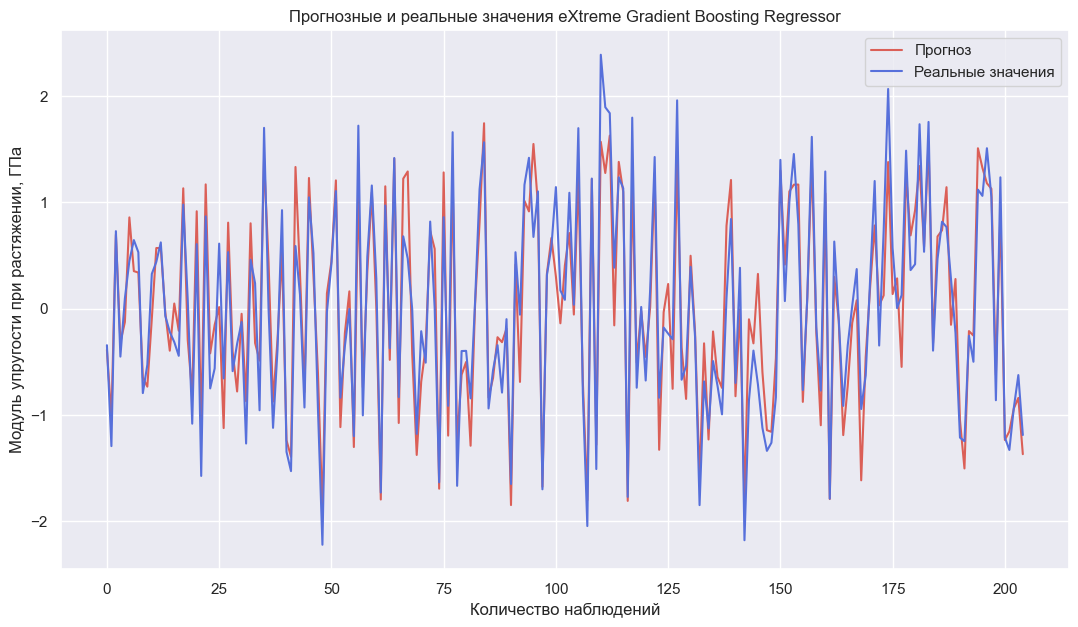

In [131]:
#Cопоставим прогнозные и реальные значения на совмещенном графике

plt.figure(figsize = (13, 7))
plt.title("Прогнозные и реальные значения eXtreme Gradient Boosting Regressor")
plt.plot(y_pred_xgbr1, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test1.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Модуль упругости при растяжении, ГПа")
plt.legend()
plt.grid(True);

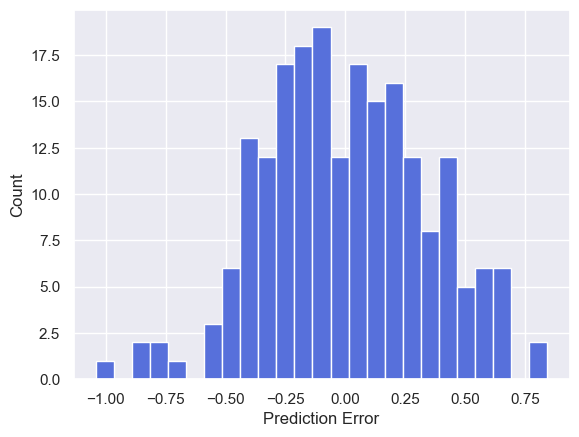

In [133]:
#Визуализация гистограммы распределения ошибки

error = y_test1 - y_pred_xgbr1
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
_ = plt.ylabel('Count')

In [135]:
#Оценим результаты обучения моделей

res_data = {'Model':['SGDR', 'SVR', 'GBR', 'XGBR'],
            'MAE':[mae_sgdr1, mae_svr1, mae_gbr1, mae_xgbr1],
            'MAPE':[mape_sgdr1, mape_svr1, mape_gbr1, mape_xgbr1],
            'MSE':[mse_sgdr1, mse_svr1, mse_gbr1, mse_xgbr1],
            'RMSE':[rmse_sgdr1, rmse_svr1, rmse_gbr1, rmse_xgbr1],
            'R2':[r2_sgdr1, r2_svr1, r2_gbr1, r2_xgbr1]}

model_result = pd.DataFrame(data=res_data)
model_result.set_index('Model', inplace=True)

final_result = (model_result.style
               .highlight_min(subset=['MAE', 'MAPE', 'MSE', 'RMSE'], color='lightgreen', axis=0)
               .highlight_max(subset=['R2'], color='lightgreen', axis=0))

final_result

,MAE,MAPE,MSE,RMSE,R2
Model,,,,,
SGDR,0.271399,1.350726,0.116279,0.340997,0.879187
SVR,0.272045,1.030820,0.114656,0.338609,0.880873
GBR,0.322576,2.061689,0.170722,0.413186,0.822620
XGBR,0.275501,1.374855,0.114859,0.338908,0.880662


## Выбор модели: по совокупности показателей, для дальнейшей работы подходит модель №2 Support Vector Regression или модель №4 eXtreme Gradient Boosting (XGBoost) Regressor ###

## Подбор моделей ML для прогнозирования переменной №2 "Прочность при растяжении"

### При подготовке данных для подбора моделей для второй переменной, необходимо сменить подход к нормализации и масштабированию данных. С этой целью все экземпляры методов будут взяты с настройками по умолчанию, а также будут применены не все методы масштабирования из ранее применявшихся.

In [138]:
# Проведем нормализацию по значениям каждого наблюдения

normliz2 = Normalizer()
composed_mat_nrm2 = pd.DataFrame(normliz2.fit_transform(composed_mat), columns=composed_mat.columns, index=composed_mat.index)

In [140]:
# Проведем масштабирование методом MinMaxScaler

minmax2 = MinMaxScaler()
mmx2 = minmax2.fit_transform(composed_mat_nrm2)
CM_mmx2 = pd.DataFrame(mmx2, columns = composed_mat_nrm2.columns)

In [142]:
# Проведем масштабирование методом StandardScaler

std2 = StandardScaler()
CM_scaled2 = std2.fit_transform(CM_mmx2)
composed_mat_std2 = pd.DataFrame(CM_scaled2, columns = CM_mmx2.columns)

In [144]:
# Переименуем столбцы для удобства дальнейших операций

composed_mat_std2.columns = ['matrix-filler',
                        'plotn',
                        'uprug_module',
                        'qty_otverd',
                        'soderj_epoxid-group',
                        'temp_flash',
                        'surface_plotn',
                        'tensile_module-t1',
                        'tensile_strength-t2',
                        'smola_consum',
                        'angle_nashiv',
                        'step_nashiv',
                        'plotn_nashiv']
composed_mat_std2.head()

,matrix-filler,plotn,uprug_module,qty_otverd,soderj_epoxid-group,temp_flash,surface_plotn,tensile_module-t1,tensile_strength-t2,smola_consum,angle_nashiv,step_nashiv,plotn_nashiv
0,-1.312890,-0.728887,-0.226820,-2.664728,-0.685283,-3.768961,-1.049735,-1.251604,1.061764,-0.344789,-0.971518,-1.219888,-0.455189
1,-1.317401,-0.749946,-0.232280,-2.102743,-0.323508,-0.629378,-1.051515,-1.270488,1.032825,-0.352899,-0.971518,-1.223316,-0.271932
2,-1.317513,-0.750467,-0.232415,-2.105656,2.027258,-0.629695,-1.051559,-1.270956,1.032108,-0.353099,-0.971518,-1.223400,0.370968
3,-1.318731,-0.756155,-0.233889,0.123108,-0.963213,-0.371356,-1.052040,-1.276056,1.024293,-0.355290,-0.971518,-0.900780,-1.110445
4,-0.481145,-0.758802,-0.194789,-0.361106,-0.706562,-0.634772,-1.052264,-1.278430,1.020655,-0.356309,-0.971518,-0.901318,-0.468971


In [146]:
#Разделим данные на наборы для модели №2, которая будет работать с целевой переменной "Прочность при растяжении"
# Также из признаков удалим признак "Модуль упругости" для обучения на данных без этого параметра

y_labels2 = composed_mat_std2['tensile_strength-t2'].copy()                                   #целевая переменная
X_features2 = composed_mat_std2.drop(['tensile_strength-t2', 'tensile_module-t1'], axis=1)    #признаки

In [148]:
X_features2

,matrix-filler,plotn,uprug_module,qty_otverd,soderj_epoxid-group,temp_flash,surface_plotn,smola_consum,angle_nashiv,step_nashiv,plotn_nashiv
0,-1.312890,-0.728887,-0.226820,-2.664728,-0.685283,-3.768961,-1.049735,-0.344789,-0.971518,-1.219888,-0.455189
1,-1.317401,-0.749946,-0.232280,-2.102743,-0.323508,-0.629378,-1.051515,-0.352899,-0.971518,-1.223316,-0.271932
2,-1.317513,-0.750467,-0.232415,-2.105656,2.027258,-0.629695,-1.051559,-0.353099,-0.971518,-1.223400,0.370968
3,-1.318731,-0.756155,-0.233889,0.123108,-0.963213,-0.371356,-1.052040,-0.355290,-0.971518,-0.900780,-1.110445
4,-0.481145,-0.758802,-0.194789,-0.361106,-0.706562,-0.634772,-1.052264,-0.356309,-0.971518,-0.901318,-0.468971
...,...,...,...,...,...,...,...,...,...,...,...
1018,-0.631100,0.068264,0.628299,-0.698779,-0.494293,0.866732,-0.955671,-1.420386,1.046053,0.851961,-0.662730
1019,0.659656,0.652128,-0.848805,1.283201,-0.558059,-0.434175,-0.415902,-1.507400,1.077423,1.465986,-0.104574
1020,0.233296,-0.348882,-1.036829,-0.142152,0.223075,-0.902674,0.839140,0.145678,0.930385,-1.061874,0.571544
1021,1.046921,0.985470,0.182044,1.259148,-0.507285,0.142570,0.734350,-0.132239,1.133240,-0.072823,0.352192


In [150]:
y_labels2

0       1.061764
1       1.032825
2       1.032108
3       1.024293
4       1.020655
          ...   
1018    0.077235
1019    0.118205
1020    0.591200
1021   -0.867723
1022    0.993423
Name: tensile_strength-t2, Length: 1023, dtype: float64

In [152]:
#Делим данные на тренировочные (train), валидационные (val) и тестовые (test) выборки
#Для получения валидационной выборки делим тестовую выборку напополам

X_train2, X_test_full, y_train2, y_test_full = train_test_split(X_features2, y_labels2, test_size=0.4, shuffle=True, random_state=42)
X_test2, X_val2, y_test2, y_val2 = train_test_split(X_test_full, y_test_full, test_size=0.5, shuffle=True, random_state=21)

In [154]:
# Проверим размеры полученных наборов

print(len(y_labels2), len(y_train2), len(y_test2), len(y_val2))
print(len(X_features2), len(X_train2), len(X_test2), len(X_val2))

1023 613 205 205
1023 613 205 205


In [156]:
# Подготовим функцию отчета о гиперпараметрах

def report(results, n_top=3):
    for i in range(1, n_top+1):
        candidates = np.flatnonzero(results["rank_test_score"] == i)
        for candidate in candidates:
            print(f'Модель на {format(i)} месте')

            print('Средняя оценка: {0:.3f} (std: {1:.3f})'.format(
                    results['mean_test_score'][candidate],
                    results['std_test_score'][candidate],)
                 )
            print(f'Гиперпараметры: {format(results["params"][candidate])}')

### Модель №1. Stochastic Gradient Descent Regressor ###

In [158]:
#Первичное обучение модели с гиперпараметрами по умолчанию и получение оценки по R2

sgdr_2 = SGDRegressor()

sgdr_2.fit(X_train2, y_train2)

score_21 = sgdr_2.score(X_train2, y_train2)
print(f'Оценка R2 после первичного обучения: {score_21}')
print(f'Начальные гиперпараметры: {sgdr_2.get_params()}')

Оценка R2 после первичного обучения: 0.9523454229592181
Начальные гиперпараметры: {'alpha': 0.0001, 'average': False, 'early_stopping': False, 'epsilon': 0.1, 'eta0': 0.01, 'fit_intercept': True, 'l1_ratio': 0.15, 'learning_rate': 'invscaling', 'loss': 'squared_error', 'max_iter': 1000, 'n_iter_no_change': 5, 'penalty': 'l2', 'power_t': 0.25, 'random_state': None, 'shuffle': True, 'tol': 0.001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


In [160]:
# Поиск лучших гиперпараметров методом случайного перебора (RandomizedSearchCV)

param_distr_sgdr2 = {'loss': ['squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'],
                     'penalty':['l1', 'l2', 'elasticnet'],
                     'alpha': [0.00001, 0.0001, 0.001, 0.1, 1],
                     'l1_ratio':[0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1],
                     'max_iter': [100, 250, 500, 750, 1000, 2000, 5000],
                     'epsilon': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
                     'learning_rate': ['constant', 'optimal', 'invscaling', 'adaptive'],
                     'eta0': [0.0001, 0.001, 0.01, 0.1, 1]}

rnd_search = RandomizedSearchCV(sgdr_2, param_distr_sgdr2, n_iter=50, scoring='r2', n_jobs=-1, cv=20, verbose=1, random_state=42)
rnd_search.fit(X_train2, y_train2)

report(rnd_search.cv_results_)

Fitting 20 folds for each of 50 candidates, totalling 1000 fits
Модель на 1 месте
Средняя оценка: 0.949 (std: 0.012)
Гиперпараметры: {'penalty': 'l2', 'max_iter': 750, 'loss': 'huber', 'learning_rate': 'adaptive', 'l1_ratio': 0.8, 'eta0': 0.01, 'epsilon': 1, 'alpha': 0.001}
Модель на 2 месте
Средняя оценка: 0.949 (std: 0.012)
Гиперпараметры: {'penalty': 'l1', 'max_iter': 250, 'loss': 'huber', 'learning_rate': 'adaptive', 'l1_ratio': 0.35, 'eta0': 1, 'epsilon': 100, 'alpha': 0.0001}
Модель на 3 месте
Средняя оценка: 0.949 (std: 0.011)
Гиперпараметры: {'penalty': 'l1', 'max_iter': 250, 'loss': 'squared_epsilon_insensitive', 'learning_rate': 'adaptive', 'l1_ratio': 1, 'eta0': 0.001, 'epsilon': 0.01, 'alpha': 1e-05}


In [162]:
# Поиск лучших гиперпараметров байесовкским методом (BayesSearchCV)
# Сюда вносим гиперпараметры от трех лучших моделей выбраных при случайном переборе

param_dict_sgdr2 = {'loss': Categorical(['squared_epsilon_insensitive', 'huber']),
                    'penalty': Categorical(['l2', 'l1']),
                    'alpha': Real(0.00001, 0.001),
                    'l1_ratio': Real(0.3, 1),
                    'max_iter': Integer(200, 800),
                    'epsilon': Real(0.01, 100),
                    'learning_rate': Categorical(['invscaling', 'adaptive']),
                    'eta0': Real(0.001, 1)}

bs_search = BayesSearchCV(sgdr_2, param_dict_sgdr2, optimizer_kwargs={'base_estimator': 'GP'}, scoring='r2', n_iter=50, n_jobs=-1, cv=10, verbose=0, random_state=42)
bs_search.fit(X_train2, y_train2)

best_parameter = bs_search.best_params_
best_scoring = bs_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Лучшие параметры: OrderedDict([('alpha', 0.0006633648024360688), ('epsilon', 33.95022689837984), ('eta0', 0.11028309140141199), ('l1_ratio', 0.3), ('learning_rate', 'adaptive'), ('loss', 'huber'), ('max_iter', 200), ('penalty', 'l2')])
Лучшая оценка: 0.9500787014246127


In [164]:
# Проведем валидацию модели с лучшими гиперпараметрами

sgdr2_best = SGDRegressor(loss='huber', penalty='l2', alpha=0.00066, l1_ratio=0.3, max_iter=200, 
                          shuffle=True, epsilon=33.95, random_state=42, learning_rate='adaptive', eta0=0.11028)

val_sgdr2 = cross_val_score(sgdr2_best, X_val2, y_val2, cv=10, n_jobs=-1, scoring='r2')
val_sgdr2

array([0.94087941, 0.94866615, 0.96660127, 0.95962812, 0.94962862,
       0.93635336, 0.93450977, 0.95192985, 0.94229638, 0.94395372])

In [166]:
# Cовместим тренировочный и валидационный наборы, затем проведем повторное обучение модели на совмещенных данных

X_train_final = np.concatenate([X_train2, X_val2])
y_train_final = np.concatenate([y_train2, y_val2])

sgdr2_best.fit(X_train_final, y_train_final)
print(f'Лучшая оценка: {sgdr2_best.score(X_train_final, y_train_final)}')

Лучшая оценка: 0.9537428038898885


In [168]:
# Проведем финальную проверку модели

y_pred_sgdr2 = sgdr2_best.predict(X_test2)

In [170]:
# Получим оценки на тестовой выборке

mae_sgdr2 = mean_absolute_error(y_pred_sgdr2, y_test2)
mape_sgdr2 = mean_absolute_percentage_error(y_pred_sgdr2, y_test2)
mse_sgdr2 = mean_squared_error(y_pred_sgdr2, y_test2)
rmse_sgdr2 = np.sqrt(mse_sgdr2)
r2_sgdr2 = sgdr2_best.score(X_test2, y_test2)

print('Оценки для SGDRegressor:')
print('Оценка MAE: {:.3f}'.format(mae_sgdr2))
print('Оценка MAPE: {:.3f}'.format(mape_sgdr2))
print('Оценка MSE: {:.3f}'.format(mse_sgdr2))
print('Оценка RMSE: {:.3f}'.format (rmse_sgdr2))
print('Оценка R2: {:.3f}'.format(r2_sgdr2))

Оценки для SGDRegressor:
Оценка MAE: 0.149
Оценка MAPE: 0.471
Оценка MSE: 0.037
Оценка RMSE: 0.191
Оценка R2: 0.962


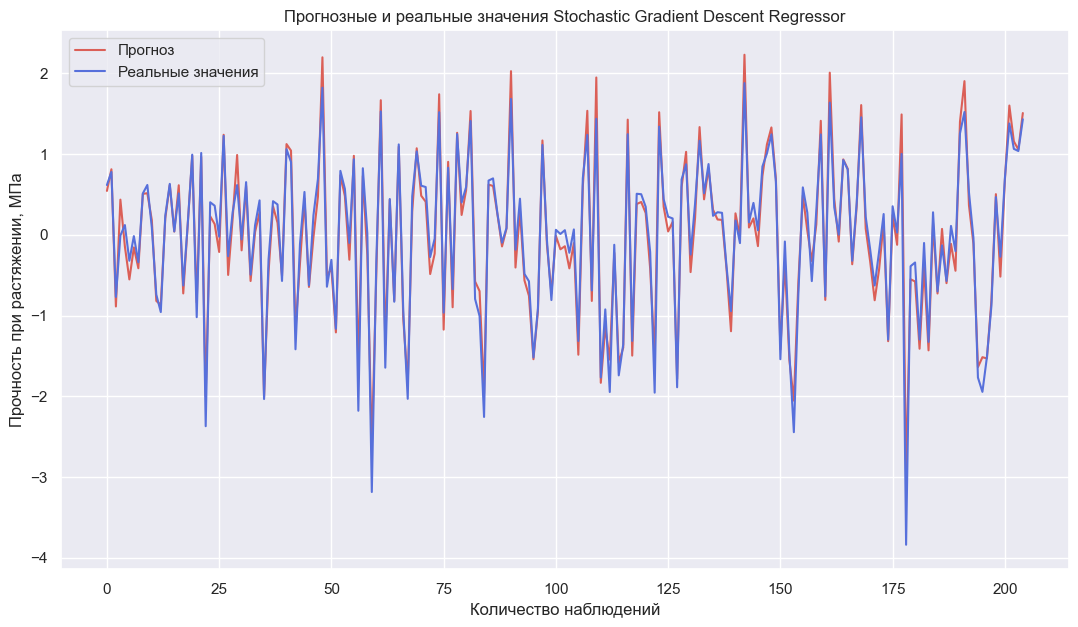

In [172]:
#Cопоставим прогнозные реальные значения на совмещенном графике

plt.figure(figsize = (13, 7))
plt.title("Прогнозные и реальные значения Stochastic Gradient Descent Regressor")
plt.plot(y_pred_sgdr2, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test2.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Прочность при растяжении, МПа")
plt.legend()
plt.grid(True);

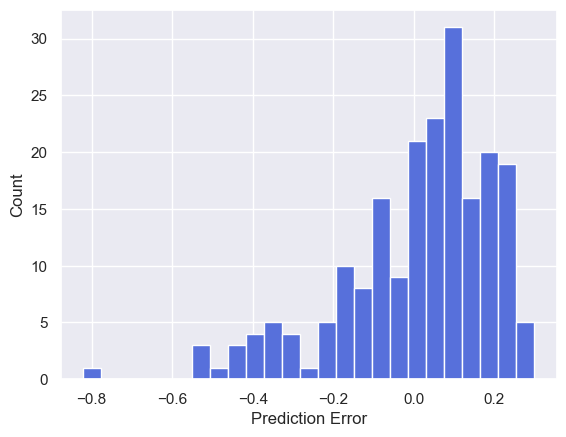

In [174]:
#Визуализация гистограммы распределения ошибки

error = y_test2 - y_pred_sgdr2
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
_ = plt.ylabel('Count')

### Модель №2. Support Vector Regression ###

In [176]:
# Первичное обучение и получение оценки по R2

svr_2 = SVR()

svr_2.fit(X_train2, y_train2)

score_22 = svr_2.score(X_train2, y_train2)
print(f'Оценка R2 после первичного обучения: {score_22}')
print(f'Начальные гиперпараметры: {svr_2.get_params()}')

Оценка R2 после первичного обучения: 0.9771827231016994
Начальные гиперпараметры: {'C': 1.0, 'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}


In [178]:
# Поиск лучших гиперпараметров методом случайного перебора (RandomizedSearchCV)

param_distr_svr2 = {'kernel': ['linear', 'poly', 'rbf'],
                    'C': [1, 10, 50, 100, 300, 500],
                    'gamma': ['scale', 'auto'],
                    'epsilon': [0.0001, 0.01, 0.1, 1, 10],
                    'degree': [1, 2, 3, 4, 5]}

rnd_search = RandomizedSearchCV(svr_2, param_distr_svr2, scoring='r2', n_iter=50, n_jobs=-1, cv=10, verbose=0, random_state=42)
rnd_search.fit(X_train2, y_train2)

report(rnd_search.cv_results_)

Модель на 1 месте
Средняя оценка: 0.950 (std: 0.030)
Гиперпараметры: {'kernel': 'rbf', 'gamma': 'auto', 'epsilon': 0.0001, 'degree': 3, 'C': 10}
Модель на 2 месте
Средняя оценка: 0.949 (std: 0.031)
Гиперпараметры: {'kernel': 'rbf', 'gamma': 'scale', 'epsilon': 0.0001, 'degree': 5, 'C': 50}
Модель на 2 месте
Средняя оценка: 0.949 (std: 0.031)
Гиперпараметры: {'kernel': 'rbf', 'gamma': 'scale', 'epsilon': 0.0001, 'degree': 4, 'C': 100}


In [180]:
# Поиск лучших гиперпараметров байесовкским методом (BayesSearchCV)
# Сюда вносим гиперпараметры от трех лучших моделей выбраных при случайном переборе

param_dict_svr2 = {'kernel': Categorical(['rbf']),
                   'C': Real(10, 100),
                   'gamma': Categorical(['scale', 'auto']),
                   'epsilon': Real(0.0001, 0.1),
                   'degree': Integer(3, 5)}

bs_search = BayesSearchCV(svr_2, param_dict_svr2, optimizer_kwargs={'base_estimator': 'GP'}, scoring='r2', n_iter=50, n_jobs=-1, cv=10, verbose=0, random_state=42)
bs_search.fit(X_train2, y_train2)

best_parameter = bs_search.best_params_
best_scoring = bs_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Лучшие параметры: OrderedDict([('C', 100.0), ('degree', 5), ('epsilon', 0.0001), ('gamma', 'auto'), ('kernel', 'rbf')])
Лучшая оценка: 0.9495606215427908


In [182]:
# Проведем валидацию модели с лучшими гиперпараметрами

svr2_best = SVR(kernel='rbf', gamma='auto', C=100, epsilon=0.0001, degree=5, shrinking=True)

val_svr2 = cross_val_score(svr2_best, X_val2, y_val2, cv=10, n_jobs=-1, scoring='r2')
val_svr2

array([0.77834381, 0.86622067, 0.79270875, 0.88617743, 0.86649162,
       0.91370063, 0.92133269, 0.98121388, 0.91168876, 0.86048501])

In [184]:
# Cовместим тренировочный и валидационный наборы, затем проведем повторное обучение модели на совмещенных данных

X_train_final = np.concatenate([X_train2, X_val2])
y_train_final = np.concatenate([y_train2, y_val2])

svr2_best.fit(X_train_final, y_train_final)
print(f'Лучшая оценка: {svr2_best.score(X_train_final, y_train_final)}')

Лучшая оценка: 0.9999999269480219


In [186]:
# Проведем финальную проверку модели

y_pred_svr2 = svr2_best.predict(X_test2)

In [188]:
# Получим оценки на тестовой выборке

mae_svr2 = mean_absolute_error(y_pred_svr2, y_test2)
mape_svr2 = mean_absolute_percentage_error(y_pred_svr2, y_test2)
mse_svr2 = mean_squared_error(y_pred_svr2, y_test2)
rmse_svr2 = np.sqrt(mse_svr2)
r2_svr2 = svr2_best.score(X_test2, y_test2)

print('Оценки для SVRegression:')
print('Оценка MAE: {:.3f}'.format(mae_svr2))
print('Оценка MAPE: {:.3f}'.format(mape_svr2))
print('Оценка MSE: {:.3f}'.format(mse_svr2))
print('Оценка RMSE: {:.3f}'.format (rmse_svr2))
print('Оценка R2: {:.3f}'.format(r2_svr2))

Оценки для SVRegression:
Оценка MAE: 0.083
Оценка MAPE: 0.357
Оценка MSE: 0.028
Оценка RMSE: 0.169
Оценка R2: 0.971


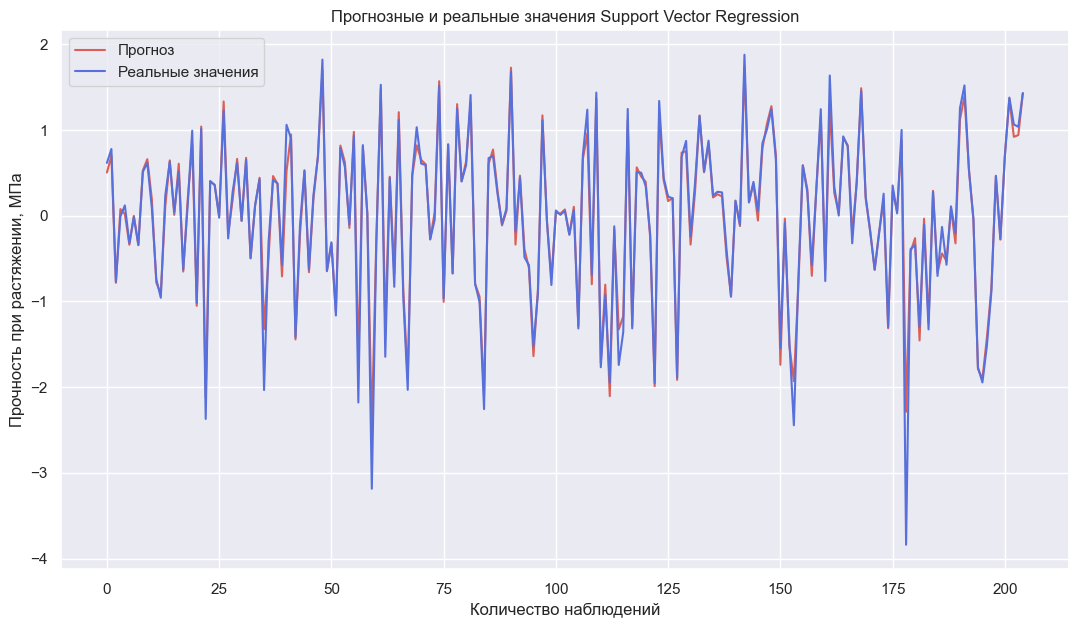

In [190]:
#Cопоставим прогнозные реальные значения на совмещенном графике

plt.figure(figsize = (13, 7))
plt.title("Прогнозные и реальные значения Support Vector Regression")
plt.plot(y_pred_svr2, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test2.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Прочность при растяжении, МПа")
plt.legend()
plt.grid(True);

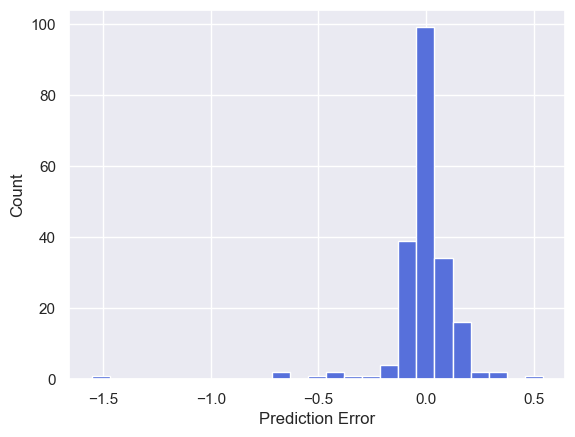

In [192]:
#Визуализация гистограммы распределения ошибки

error = y_test2 - y_pred_svr2
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
_ = plt.ylabel('Count')

### Модель №3. Gradient Boosting Regressor ###

In [194]:
# Первичное обучение и получение оценки по R2

gbr_2 = GradientBoostingRegressor(random_state=42)

gbr_2.fit(X_train2, y_train2)

score_23 = gbr_2.score(X_train2, y_train2)
print(f'Оценка R2 после первичного обучения: {score_23}')
print(f'Начальные гиперпараметры: {gbr_2.get_params()}')

Оценка R2 после первичного обучения: 0.9977532037053802
Начальные гиперпараметры: {'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': 'friedman_mse', 'init': None, 'learning_rate': 0.1, 'loss': 'squared_error', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


In [196]:
# Поиск лучших гиперпараметров методом случайного перебора (RandomizedSearchCV)

param_distr_gbr2 = {'n_estimators': [10, 20, 30, 40, 50, 80, 100, 300, 500, 800, 1000],
                    'learning_rate': [0.001, 0.01, 0.05, 0.1, 0.2, 0.5, 1],
                    'max_depth': [1, 2, 3, 5, 8, 10],
                    'min_samples_split': [2, 5, 10, 20],
                    'min_samples_leaf': [1, 2, 4, 8],
                    'subsample': [0.6, 0.8, 1.0, 2.0, 4.0],
                    'max_features': ["sqrt", "log2", None]}

rnd_search = RandomizedSearchCV(gbr_2, param_distr_gbr2, n_iter=50, scoring='r2', n_jobs=-1, cv=20, verbose=1, random_state=42)
rnd_search.fit(X_train2, y_train2)

report(rnd_search.cv_results_)

Fitting 20 folds for each of 50 candidates, totalling 1000 fits
Модель на 1 месте
Средняя оценка: 0.977 (std: 0.013)
Гиперпараметры: {'subsample': 0.8, 'n_estimators': 1000, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 3, 'learning_rate': 0.1}
Модель на 2 месте
Средняя оценка: 0.976 (std: 0.011)
Гиперпараметры: {'subsample': 0.6, 'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 10, 'learning_rate': 0.1}
Модель на 3 месте
Средняя оценка: 0.971 (std: 0.015)
Гиперпараметры: {'subsample': 0.8, 'n_estimators': 80, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 5, 'learning_rate': 0.05}


In [198]:
# Поиск лучших гиперпараметров байесовкским методом (BayesSearchCV)
# Сюда вносим гиперпараметры от трех лучших моделей выбраных при случайном переборе

param_dict_gbr2 = {'n_estimators': Integer(80, 1000),
                   'learning_rate': Real(0.01, 0.1),
                   'max_depth': Integer(3, 10),
                   'min_samples_split': Integer(2, 5),
                   'min_samples_leaf': Integer(2, 4),
                   'subsample': Real(0.6, 0.8),
                   'max_features': Categorical(['sqrt', None])}

bs_search = BayesSearchCV(gbr_2, param_dict_gbr2, optimizer_kwargs={'base_estimator':'GBRT'}, scoring='r2', n_iter=50, n_jobs=-1, cv=10, verbose=0, random_state=42)
bs_search.fit(X_train2, y_train2)

best_parameter = bs_search.best_params_
best_scoring = bs_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Лучшие параметры: OrderedDict([('learning_rate', 0.021853869908190736), ('max_depth', 4), ('max_features', None), ('min_samples_leaf', 2), ('min_samples_split', 2), ('n_estimators', 748), ('subsample', 0.6027106521900315)])
Лучшая оценка: 0.9813492857732615


In [200]:
# Проведем валидацию модели с лучшими гиперпараметрами

gbr2_best = GradientBoostingRegressor(n_estimators=748, learning_rate=0.02185, max_depth=2, min_samples_split=2, 
                                      min_samples_leaf=2, subsample= 0.6027, max_features=None, random_state=42)

val_gbr2 = cross_val_score(gbr2_best, X_val2, y_val2, cv=10, n_jobs=-1, scoring='r2')
val_gbr2

array([0.91544467, 0.95620909, 0.981112  , 0.98386298, 0.98109292,
       0.95914505, 0.97915724, 0.97522603, 0.94428006, 0.9870258 ])

In [202]:
# Cовместим тренировочный и валидационный наборы, затем проведем повторное обучение модели на совмещенных данных

X_train_final = np.concatenate([X_train2, X_val2])
y_train_final = np.concatenate([y_train2, y_val2])

gbr2_best.fit(X_train_final, y_train_final)
print(f'Лучшая оценка: {gbr2_best.score(X_train_final, y_train_final)}')

Лучшая оценка: 0.99760445443597


In [204]:
# Проведем финальную проверку модели

y_pred_gbr2 = gbr2_best.predict(X_test2)

In [206]:
# Получим оценки на тестовой выборке

mae_gbr2 = mean_absolute_error(y_pred_gbr2, y_test2)
mape_gbr2 = mean_absolute_percentage_error(y_pred_gbr2, y_test2)
mse_gbr2 = mean_squared_error(y_pred_gbr2, y_test2)
rmse_gbr2 = np.sqrt(mse_gbr2)
r2_gbr2 = gbr2_best.score(X_test2, y_test2)

print('Оценки для Gradient Boosting Regressor:')
print('Оценка MAE: {:.3f}'.format(mae_gbr2))
print('Оценка MAPE: {:.3f}'.format(mape_gbr2))
print('Оценка MSE: {:.3f}'.format(mse_gbr2))
print('Оценка RMSE: {:.3f}'.format (rmse_gbr2))
print('Оценка R2: {:.3f}'.format(r2_gbr2))

Оценки для Gradient Boosting Regressor:
Оценка MAE: 0.056
Оценка MAPE: 0.347
Оценка MSE: 0.008
Оценка RMSE: 0.092
Оценка R2: 0.991


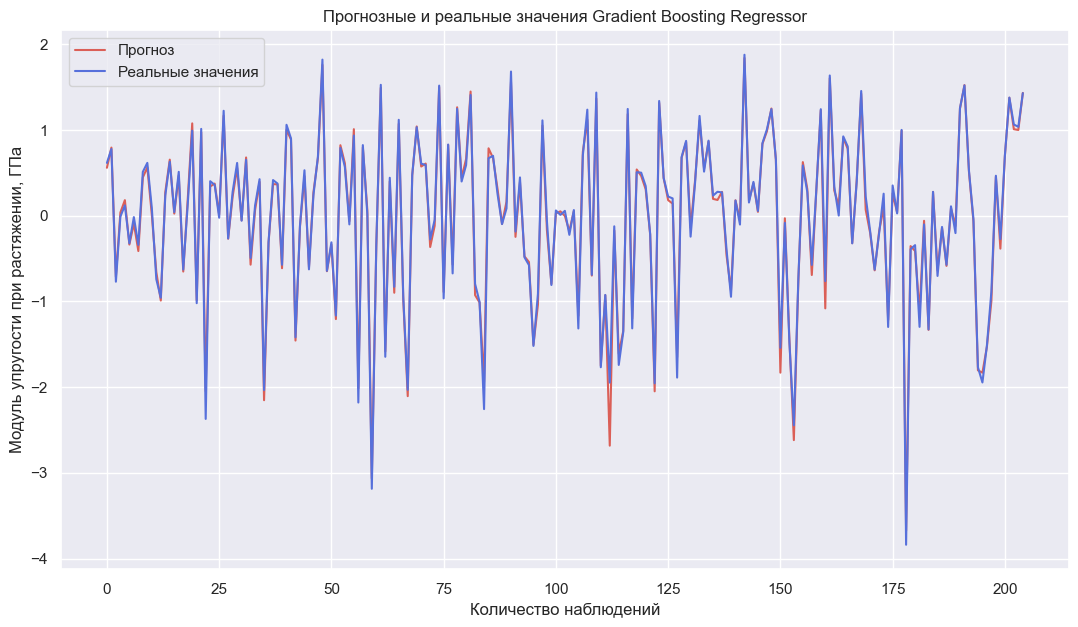

In [208]:
#Cопоставим прогнозные реальные значения на совмещенном графике

plt.figure(figsize = (13, 7))
plt.title("Прогнозные и реальные значения Gradient Boosting Regressor")
plt.plot(y_pred_gbr2, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test2.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Модуль упругости при растяжении, ГПа")
plt.legend()
plt.grid(True);

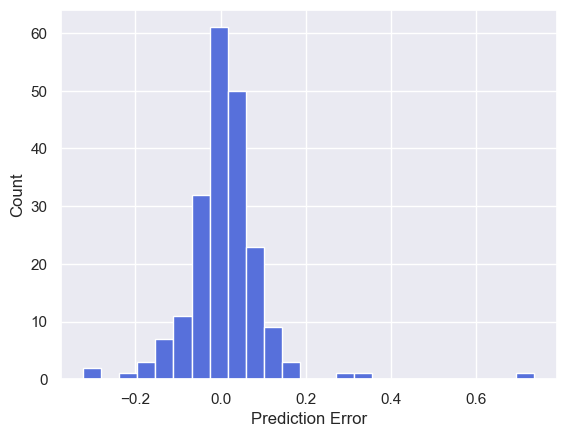

In [210]:
#Визуализация гистограммы распределения ошибки

error = y_test2 - y_pred_gbr2
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
_ = plt.ylabel('Count')

### Модель №4. eXtreme Gradient Boosting (XGBoost) Regressor ###

In [212]:
# Первичное обучение и получение оценки по R2

xgbr_2 = XGBRegressor (objective='reg:squarederror', eval_metric='mae', random_state=42)

xgbr_2.fit(X_train2, y_train2)

score_24 = xgbr_2.score(X_train2, y_train2)
print(f'Оценка R2 после первичного обучения: {score_24}')
print(f'Начальные гиперпараметры: {xgbr_2.get_xgb_params()}')

Оценка R2 после первичного обучения: 0.9999991077751317
Начальные гиперпараметры: {'objective': 'reg:squarederror', 'base_score': None, 'booster': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'eval_metric': 'mae', 'gamma': None, 'grow_policy': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'monotone_constraints': None, 'multi_strategy': None, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}


In [214]:
# Поиск лучших гиперпараметров методом случайного перебора (RandomizedSearchCV)

param_distr_xgbr2 = {'booster': ['gbtree', 'gblinear', 'dart'], 
                     'n_estimators': [10, 50, 80, 100, 500, 800, 1000],
                     'max_depth': [4, 5, 6, 7, 8],
                     'learning_rate': [0.01, 0.02, 0.08, 0.09, 0.1, 0.2, 0.3],
                     'subsample': [0.5, 0.6, 0.7, 0.8, 0.9, 1],
                     'colsample_bytree': [0.5, 0.6, 0.7, 0.9, 1],
                     'min_child_weight': [1, 4, 5, 6, 8],
                     'gamma': [0, 0.1, 0.2, 0.4, 0.5, 1.0],
                     'reg_alpha': [0, 0.04, 0.05, 0.1, 0.4, 0.5, 1],
                     'reg_lambda': [0, 0.04, 0.09, 0.1, 0.5, 0.7, 1]}

rnd_search = RandomizedSearchCV(xgbr_2, param_distr_xgbr2, n_iter=50, scoring='r2', n_jobs=-1, cv=20, verbose=1, random_state=42)
rnd_search.fit(X_train2, y_train2)

report(rnd_search.cv_results_)

Fitting 20 folds for each of 50 candidates, totalling 1000 fits
Модель на 1 месте
Средняя оценка: 0.966 (std: 0.018)
Гиперпараметры: {'subsample': 0.8, 'reg_lambda': 0.7, 'reg_alpha': 0.4, 'n_estimators': 800, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.09, 'gamma': 0.1, 'colsample_bytree': 1, 'booster': 'gbtree'}
Модель на 2 месте
Средняя оценка: 0.965 (std: 0.017)
Гиперпараметры: {'subsample': 0.6, 'reg_lambda': 0.1, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 6, 'max_depth': 4, 'learning_rate': 0.2, 'gamma': 0.2, 'colsample_bytree': 1, 'booster': 'gbtree'}
Модель на 3 месте
Средняя оценка: 0.964 (std: 0.019)
Гиперпараметры: {'subsample': 0.7, 'reg_lambda': 0, 'reg_alpha': 1, 'n_estimators': 500, 'min_child_weight': 4, 'max_depth': 8, 'learning_rate': 0.2, 'gamma': 0.1, 'colsample_bytree': 1, 'booster': 'gbtree'}


In [216]:
# Поиск лучших гиперпараметров байесовкским методом (BayesSearchCV)
# Сюда вносим гиперпараметры от трех лучших моделей выбраных при случайном переборе

param_dict_xgbr2 = {'booster': Categorical(['gbtree']), 
                    'n_estimators': Integer(500, 800),
                    'max_depth': Integer(4, 8),
                    'learning_rate': Real(0.09, 0.2),
                    'subsample': Real(0.6, 0.8),
                    'colsample_bytree': Real(0.6, 1),
                    'min_child_weight': Integer(1, 6),
                    'gamma': Real(0.1, 0.2),
                    'reg_alpha': Real(0, 1),
                    'reg_lambda': Real(0, 0.7)}

bs_search = BayesSearchCV(xgbr_2, param_dict_xgbr2, optimizer_kwargs={'base_estimator':'GBRT'}, scoring='r2', n_iter=50, n_jobs=-1, cv=10, verbose=0, random_state=42)
bs_search.fit(X_train2, y_train2)

best_parameter = bs_search.best_params_
best_scoring = bs_search.best_score_

print(f'Лучшие параметры: {best_parameter}')
print(f'Лучшая оценка: {best_scoring}')

Лучшие параметры: OrderedDict([('booster', 'gbtree'), ('colsample_bytree', 0.9964482835189876), ('gamma', 0.1282950960200661), ('learning_rate', 0.10350218863815266), ('max_depth', 5), ('min_child_weight', 5), ('n_estimators', 501), ('reg_alpha', 0.10535354548295697), ('reg_lambda', 0.3436402389802752), ('subsample', 0.6139926725248832)])
Лучшая оценка: 0.9694354102733399


In [218]:
# Проведем валидацию модели с лучшими гиперпараметрами

xgbr2_best = XGBRegressor(objective='reg:squarederror', eval_metric='mae', booster='gbtree', 
                          n_estimators=501, learning_rate=0.1035, max_depth=5, gamma=0.128295, colsample_bytree=0.996448,
                          min_child_weight=5, subsample=0.61399, reg_alpha=0.10535, reg_lambda=0.3436, random_state=42)

val_xgbr2 = cross_val_score(xgbr2_best, X_val2, y_val2, cv=10, n_jobs=-1, scoring='r2')
val_xgbr2

array([0.92865952, 0.91447363, 0.95980249, 0.9364145 , 0.96391722,
       0.94659864, 0.96177057, 0.95264422, 0.88922612, 0.95287755])

In [220]:
# Cовместим тренировочный и валидационный наборы, затем проведем повторное обучение модели на совмещенных данных

X_train_final = np.concatenate([X_train2, X_val2])
y_train_final = np.concatenate([y_train2, y_val2])

xgbr2_best.fit(X_train_final, y_train_final)
print(f'Лучшая оценка: {xgbr2_best.score(X_train_final, y_train_final)}')

Лучшая оценка: 0.9945461872929605


In [222]:
# Проведем финальную проверку модели

y_pred_xgbr2 = xgbr2_best.predict(X_test2)

In [224]:
# Получим оценки на тестовой выборке

mae_xgbr2 = mean_absolute_error(y_pred_xgbr2, y_test2)
mape_xgbr2 = mean_absolute_percentage_error(y_pred_xgbr2, y_test2)
mse_xgbr2 = mean_squared_error(y_pred_xgbr2, y_test2)
rmse_xgbr2 = np.sqrt(mse_xgbr2)
r2_xgbr2 = xgbr2_best.score(X_test2, y_test2)

print('Оценки для eXtreme Gradient Boosting Regressor:')
print('Оценка MAE: {:.3f}'.format(mae_xgbr2))
print('Оценка MAPE: {:.3f}'.format(mape_xgbr2))
print('Оценка MSE: {:.3f}'.format(mse_xgbr2))
print('Оценка RMSE: {:.3f}'.format (rmse_xgbr2))
print('Оценка R2: {:.3f}'.format(r2_xgbr2))

Оценки для eXtreme Gradient Boosting Regressor:
Оценка MAE: 0.098
Оценка MAPE: 0.393
Оценка MSE: 0.025
Оценка RMSE: 0.159
Оценка R2: 0.974


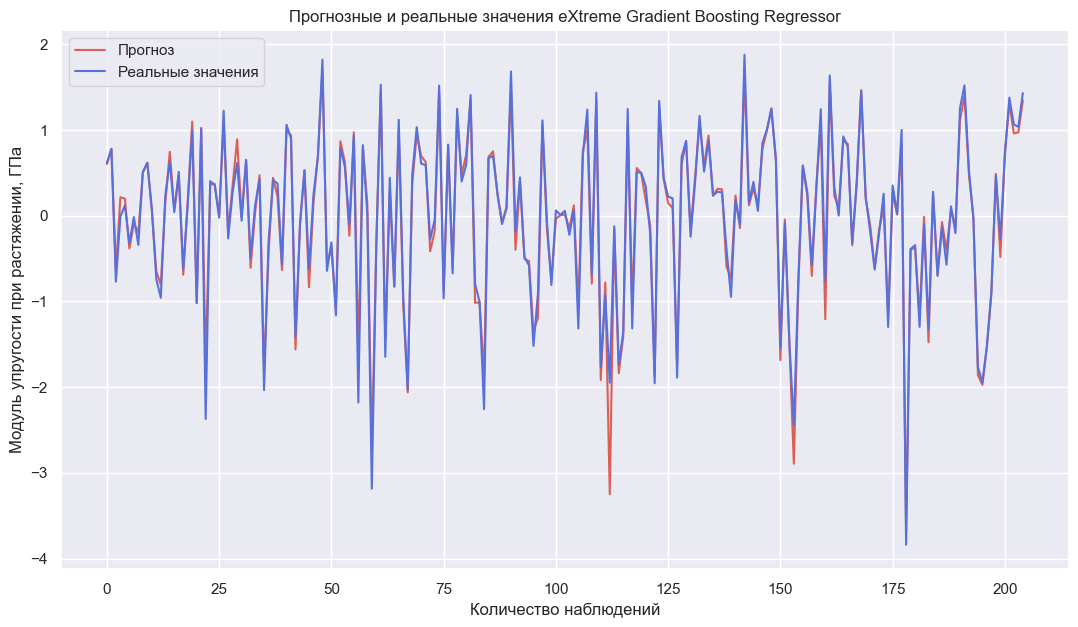

In [226]:
#Cопоставим прогнозные реальные значения на совмещенном графике

plt.figure(figsize = (13, 7))
plt.title("Прогнозные и реальные значения eXtreme Gradient Boosting Regressor")
plt.plot(y_pred_xgbr2, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test2.values, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Модуль упругости при растяжении, ГПа")
plt.legend()
plt.grid(True);

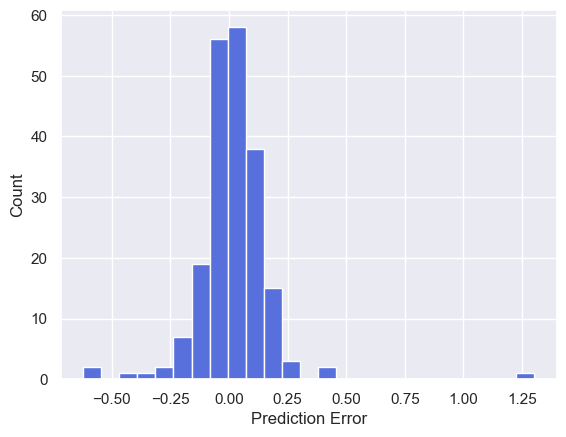

In [228]:
#Визуализация гистограммы распределения ошибки

error = y_test2 - y_pred_xgbr2
sns.set_style ('darkgrid')
plt.hist(error, bins = 25, color=selected_palette[5])
plt.xlabel('Prediction Error')
_ = plt.ylabel('Count')

In [230]:
#Оценим результаты обучения моделей

res_data2 = {'Model':['SGDR', 'SVR', 'GBR', 'XGBR'],
            'MAE':[mae_sgdr2, mae_svr2, mae_gbr2, mae_xgbr2],
            'MAPE':[mape_sgdr2, mape_svr2, mape_gbr2, mape_xgbr2],
            'MSE':[mse_sgdr2, mse_svr2, mse_gbr2, mse_xgbr2],
            'RMSE':[rmse_sgdr2, rmse_svr2, rmse_gbr2, rmse_xgbr2],
            'R2':[r2_sgdr2, r2_svr2, r2_gbr2, r2_xgbr2]}

model2_result = pd.DataFrame(data=res_data2)
model2_result.set_index('Model', inplace=True)

final_result2 = (model2_result.style
               .highlight_min(subset=['MAE', 'MAPE', 'MSE', 'RMSE'], color='lightgreen', axis=0)
               .highlight_max(subset=['R2'], color='lightgreen', axis=0))

final_result2

,MAE,MAPE,MSE,RMSE,R2
Model,,,,,
SGDR,0.149348,0.471096,0.036652,0.191446,0.962129
SVR,0.082589,0.357393,0.028445,0.168658,0.970609
GBR,0.056236,0.346752,0.008404,0.091675,0.991316
XGBR,0.098360,0.392906,0.025399,0.159370,0.973756


### Выбор модели: по совокупности показателей, лучше всего для дальнейшей работы подходит модель №3 Gradient Boosting Regressor

## Разработка нейросети для прогнозирования переменной №3 "Соотношение матрица-наполнитель"

In [14]:
normliz3 = Normalizer()
composed_mat_nrm3 = pd.DataFrame(normliz3.fit_transform(composed_mat), columns=composed_mat.columns, index=composed_mat.index)

In [16]:
rscaler3 = RobustScaler()
rscaled3 = rscaler3.fit_transform(composed_mat_nrm3)
CM_rscaled3 = pd.DataFrame(rscaled3, columns = composed_mat_nrm3.columns)

In [18]:
minmax3 = MinMaxScaler()
mmx3 = minmax3.fit_transform(CM_rscaled3)
composed_mat_std3 = pd.DataFrame(mmx3, columns = CM_rscaled3.columns)

In [20]:
composed_mat_std3.columns = ['matrix-filler',
                        'plotn',
                        'uprug_module',
                        'qty_otverd',
                        'soderj_epoxid-group',
                        'temp_flash',
                        'surface_plotn',
                        'tensile_module-t1',
                        'tensile_strength-t2',
                        'smola_consum',
                        'angle_nashiv',
                        'step_nashiv',
                        'plotn_nashiv']
composed_mat_std3.head()

,matrix-filler,plotn,uprug_module,qty_otverd,soderj_epoxid-group,temp_flash,surface_plotn,tensile_module-t1,tensile_strength-t2,smola_consum,angle_nashiv,step_nashiv,plotn_nashiv
0,0.210267,0.278489,0.378334,0.051030,0.285340,0.000000,0.136050,0.203931,0.835756,0.360724,0.0,0.217731,0.381810
1,0.209534,0.275310,0.377332,0.128683,0.341341,0.409628,0.135689,0.201132,0.831037,0.359562,0.0,0.217156,0.400845
2,0.209516,0.275231,0.377307,0.128281,0.705227,0.409587,0.135680,0.201063,0.830921,0.359533,0.0,0.217142,0.467622
3,0.209318,0.274372,0.377037,0.436244,0.242318,0.443293,0.135583,0.200307,0.829646,0.359219,0.0,0.271234,0.313750
4,0.345317,0.273973,0.384214,0.369337,0.282046,0.408925,0.135538,0.199955,0.829053,0.359073,0.0,0.271143,0.380379


In [22]:
#Подготовим данные для обучения нейросети

y = pd.DataFrame(composed_mat_std3['matrix-filler'])
X = composed_mat_std3.drop(['matrix-filler'], axis=1)

X_train3, X_test_t, y_train3, y_test_t = train_test_split(X, y, test_size=0.3, random_state=42)
X_test3, X_val3, y_test3, y_val3 = train_test_split(X_test_t, y_test_t, test_size=0.5, random_state=42)

In [24]:
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train3)
X_val_scaled = scaler_X.transform(X_val3)
X_test_scaled = scaler_X.transform(X_test3)

scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train3)
y_val_scaled = scaler_y.transform(y_val3)
y_test_scaled = scaler_y.transform(y_test3)

In [26]:

model_mf = Sequential([Input(shape=(12,)),
                       Dense(144, kernel_regularizer=l2(1e-3)),
                       BatchNormalization(),
                       Activation('silu'),
                       
                       Dense(128, kernel_regularizer=l2(1e-3)),
                       BatchNormalization(),
                       Activation('silu'),

                       Dense(128, kernel_regularizer=l2(1e-3)),
                       BatchNormalization(),
                       Activation('silu'),
                       Dropout(0.3),
                       
                       Dense(64, kernel_regularizer=l2(1e-3)),
                       BatchNormalization(),
                       Activation('silu'),

                       Dense(64, kernel_regularizer=l2(1e-3)),
                       BatchNormalization(),
                       Activation('silu'),
                       Dropout(0.3),
                       
                       Dense(32, kernel_regularizer=l2(1e-3)),
                       BatchNormalization(),
                       Activation('silu'),

                       Dense(32, kernel_regularizer=l2(1e-3)),
                       BatchNormalization(),
                       Activation('silu'),
                       Dropout(0.3),

                       Dense(16, kernel_regularizer=l2(1e-3)),
                       BatchNormalization(),
                       Activation('silu'),
                       
                       Dense(12, kernel_regularizer=l2(1e-3)),
                       BatchNormalization(),
                       Activation('silu'),
                       
                       Dense(1, activation='linear')])
model_mf.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 144)               1872      
                                                                 
 batch_normalization (BatchN  (None, 144)              576       
 ormalization)                                                   
                                                                 
 activation (Activation)     (None, 144)               0         
                                                                 
 dense_1 (Dense)             (None, 128)               18560     
                                                                 
 batch_normalization_1 (Batc  (None, 128)              512       
 hNormalization)                                                 
                                                                 
 activation_1 (Activation)   (None, 128)               0

In [28]:

model_mf.compile(loss='mean_squared_error',
                 optimizer=Adam(learning_rate=0.001),
                 metrics=['mae', tf.keras.metrics.RootMeanSquaredError()])

In [30]:

early_stop = EarlyStopping(monitor='val_loss', patience=30, min_delta=1e-4, restore_best_weights=True)
reduce_lr = ReduceLROnPlateaureduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-5, verbose=1)

learn = model_mf.fit(X_train_scaled, y_train_scaled, epochs=300, 
                     validation_data=(X_val_scaled, y_val_scaled), 
                     verbose=1, callbacks=[early_stop, reduce_lr])


Epoch 1/300
23/23 [==============================] - 5s 50ms/step - loss: 2.1337 - mae: 0.9750 - root_mean_squared_error: 1.2580 - val_loss: 1.6220 - val_mae: 0.8451 - val_root_mean_squared_error: 1.0346 - lr: 0.0010
Epoch 2/300
23/23 [==============================] - 1s 27ms/step - loss: 1.7274 - mae: 0.8463 - root_mean_squared_error: 1.0843 - val_loss: 1.6188 - val_mae: 0.8441 - val_root_mean_squared_error: 1.0330 - lr: 0.0010
Epoch 3/300
23/23 [==============================] - 1s 28ms/step - loss: 1.6523 - mae: 0.8363 - root_mean_squared_error: 1.0492 - val_loss: 1.6155 - val_mae: 0.8425 - val_root_mean_squared_error: 1.0316 - lr: 0.0010
Epoch 4/300
23/23 [==============================] - 1s 26ms/step - loss: 1.6520 - mae: 0.8144 - root_mean_squared_error: 1.0493 - val_loss: 1.6091 - val_mae: 0.8396 - val_root_mean_squared_error: 1.0288 - lr: 0.0010
Epoch 5/300
23/23 [==============================] - 1s 26ms/step - loss: 1.6069 - mae: 0.8041 - root_mean_squared_error: 1.0279 - v

In [32]:
y_pred_scaled = model_mf.predict(X_test_scaled)

5/5 [==============================] - 0s 5ms/step


In [34]:

y_pred31 = scaler_y.inverse_transform(y_pred_scaled)
y_test31 = scaler_y.inverse_transform(y_test_scaled)

print(y_test31.shape, y_pred31.shape)

y_test3i = y_test31.ravel()
y_pred3i = y_pred31.ravel()

print("Bias:", np.mean(y_pred3i - y_test3i))
print("Corr:", np.corrcoef(y_test3i, y_pred3i)[0,1])

(153, 1) (153, 1)
Bias: -0.009615753691315345
Corr: 0.28346074980343555


In [36]:

mae = mean_absolute_error(y_test3i, y_pred3i)
mape = mean_absolute_percentage_error(y_test3i, y_pred3i)
mse = mean_squared_error(y_test3i, y_pred3i)
rmse = np.sqrt(mse)
r2 = r2_score(y_test3i, y_pred3i)

# print(y_test3.shape, y_pred3.shape)

print('Результаты нейросети:')
print(f'MAE  = {mae:.4f}')
print(f'MAPE = {mape:.4f}')
print(f'MSE  = {mse:.4f}')
print(f'RMSE = {rmse:.4f}')
print(f'R2   = {r2:.4f}')

Результаты нейросети:
MAE  = 0.1262
MAPE = 0.3731
MSE  = 0.0234
RMSE = 0.1528
R2   = 0.0766


<Axes: >

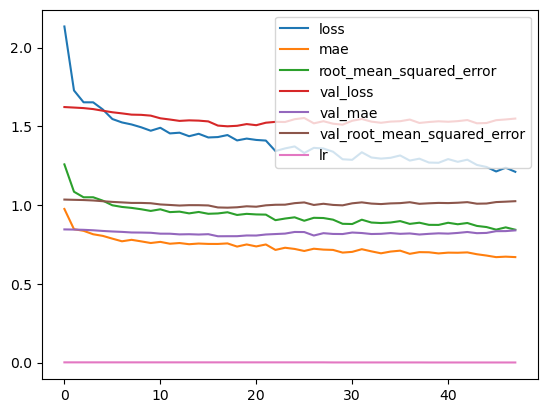

In [38]:

pd.DataFrame(learn.history).plot()

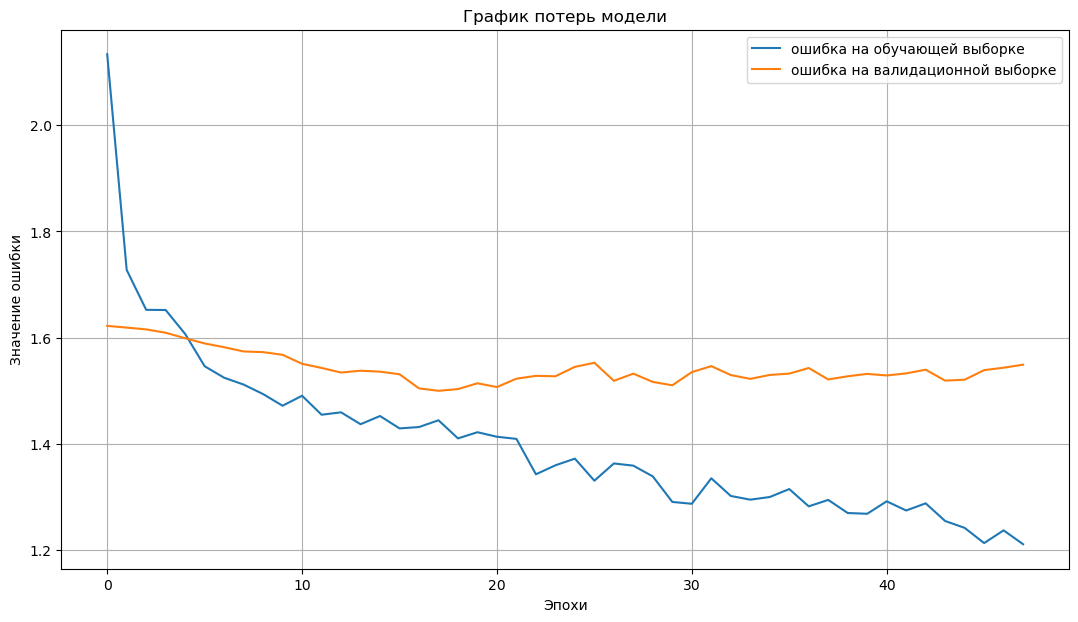

In [40]:
# Посмотрим на график потерь на тренировочной и тестовой выборках
def model_loss_plot(learn):
    plt.figure(figsize=(13,7))
    plt.plot(learn.history['loss'], label='ошибка на обучающей выборке')
    if 'val_loss' in learn.history:
        plt.plot(learn.history['val_loss'], label='ошибка на валидационной выборке')
    plt.title('График потерь модели')
    plt.xlabel('Эпохи')
    plt.ylabel('Значение ошибки')
    plt.legend()
    plt.grid(True)
    plt.show()

model_loss_plot(learn)

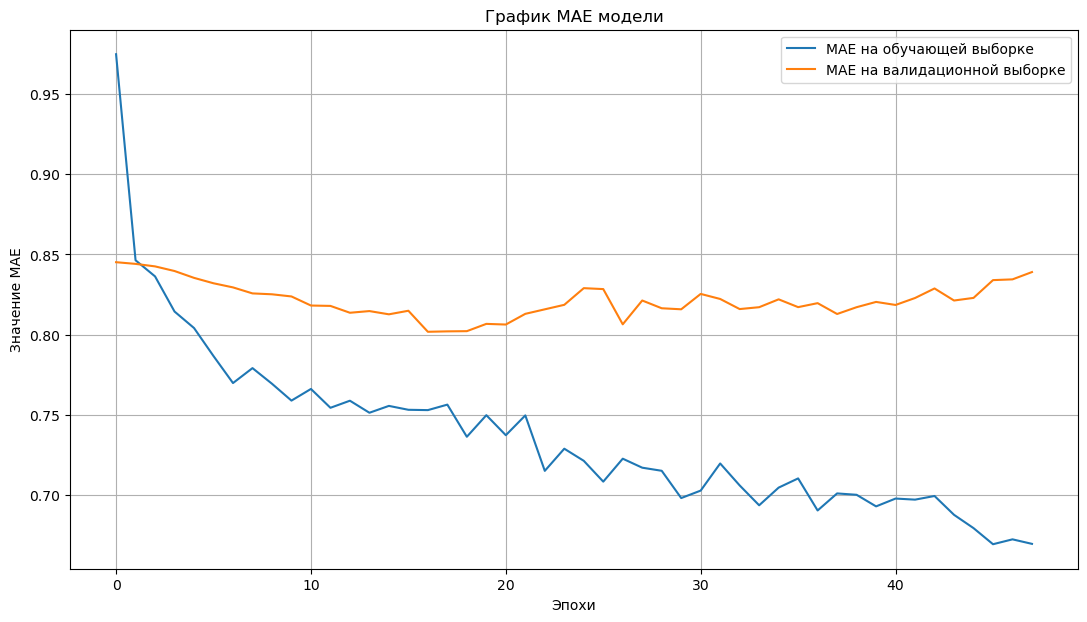

In [42]:
def model_mae_plot(learn):
    plt.figure(figsize=(13,7))
    plt.plot(learn.history['mae'], label='MAE на обучающей выборке')
    if 'val_mae' in learn.history:
        plt.plot(learn.history['val_mae'], label='MAE на валидационной выборке')
    plt.title('График MAE модели')
    plt.xlabel('Эпохи')
    plt.ylabel('Значение MAE')
    plt.legend()
    plt.grid(True)
    plt.show()

model_mae_plot(learn)

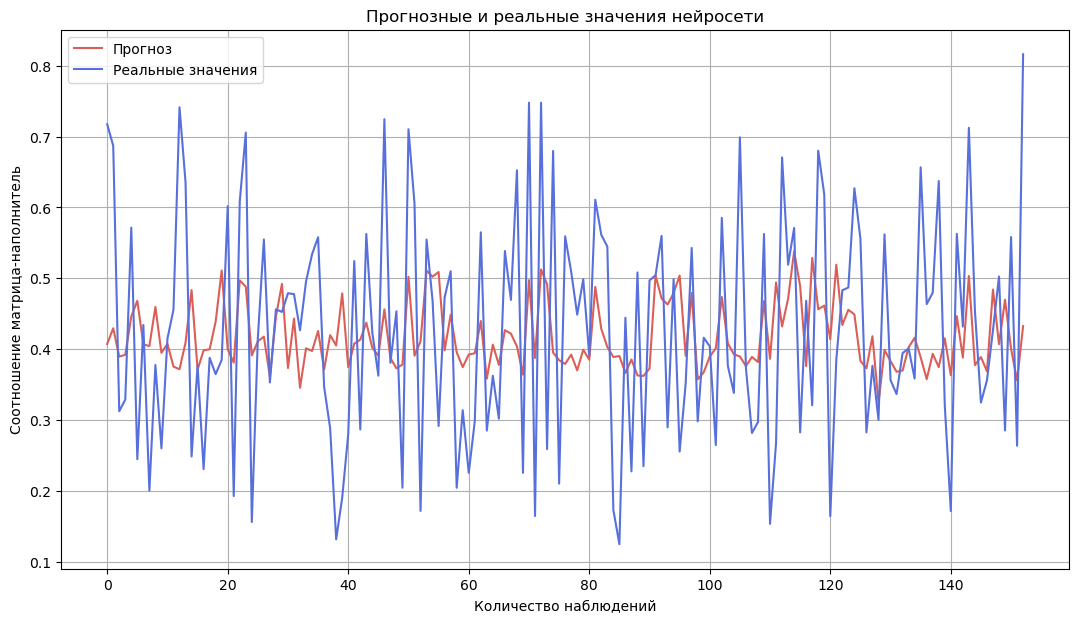

In [44]:
plt.figure(figsize = (13,7))
plt.title("Прогнозные и реальные значения нейросети")
plt.plot(y_pred3i, label = "Прогноз", color = selected_palette[0])
plt.plot(y_test3i, label = "Реальные значения", color = selected_palette[5])
plt.xlabel("Количество наблюдений")
plt.ylabel("Соотношение матрица-наполнитель")
plt.legend()
plt.grid(True);

In [47]:
print("y_test3 stats:")
print("min:", y_test3i.min(), "max:", y_test3i.max(), "mean:", y_test3i.mean())

print("\ny_pred3 stats:")
print("min:", y_pred3i.min(), "max:", y_pred3i.max(), "mean:", y_pred3i.mean())

y_test3 stats:
min: 0.12474080243143659 max: 0.81630457911758 mean: 0.4269643645007413

y_pred3 stats:
min: 0.29897785 max: 0.63174325 mean: 0.40760577


In [39]:
# from sklearn.neighbors import NearestNeighbors

# nn = NearestNeighbors(n_neighbors=5)
# nn.fit(X_train_scaled)

# idx = nn.kneighbors(X_test_scaled, return_distance=False)

# for i in range(5):
#     print("Real y:", y_test3[i])
#     print("Neighbors y:", y_train3.iloc[idx[i]].values)
#     print("-----")


Real y: 3.3076966049154795
Neighbors y: [2.37903618 2.55798519 4.41197364 2.80656327 3.04205464]
-----
Real y: 3.9731078689182606
Neighbors y: [2.66940367 2.99615411 4.45711999 3.40176085 2.68392882]
-----
Real y: 1.7127833946205002
Neighbors y: [1.82149183 2.77697872 2.76315892 1.56317078 2.2745923 ]
-----
Real y: 2.7557425025616604
Neighbors y: [2.51684907 3.02706914 3.1704395  1.48335166 1.87438926]
-----
Real y: 3.09745072225443
Neighbors y: [4.31566578 2.12442441 3.8727532  2.89701327 2.04093057]
-----


### Наброски новых решений в 2025 году ###

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train3)
X_val_scaled = scaler.transform(X_val3)
X_test_scaled = scaler.transform(X_test3)

from tensorflow.keras import layers

mf_nn = Sequential([
    layers.Input(shape=(6,)),           
    layers.Dense(128, activation='linear'),
    layers.Dense(64, activation='linear'),
    layers.Dense(32, activation='linear'),
    layers.Dense(1, activation='silu')
])

mf_nn.compile(
    loss='mean_squared_error',
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    metrics=['mae']
)

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=50,
    restore_best_weights=True
)

learn = mf_nn.fit(
    X_train_scaled, y_train3,
    validation_data=(X_val_scaled, y_val3),
    epochs=100,
    verbose=0,
    callbacks=[early_stop]
)

print(learn.params)

def model_plot(learn, metric='loss'):
    plt.figure(figsize=(15,5))
    plt.plot(learn.history[metric], label=f'{metric} на обучающей')
    if f'val_{metric}' in learn.history:
        plt.plot(learn.history[f'val_{metric}'], label=f'{metric} на валидационной')
    plt.xlabel('Эпохи')
    plt.ylabel(metric)
    plt.title(f'График {metric} модели')
    plt.legend()
    plt.grid(True)
    plt.show()

model_plot(learn, 'loss')
model_plot(learn, 'mae')

y_pred_scaled = mf_nn.predict(X_test_scaled)

plt.figure(figsize=(12,7))
plt.title("Прогнозные и реальные значения нейросети")
plt.plot(y_pred_scaled, label="Прогноз", color='blue', linewidth=2)
plt.scatter(range(len(y_test3)), y_test3.values, label="Реальные", color='orange', s=15, alpha=0.6)
plt.xlabel("Наблюдения")
plt.ylabel("Соотношение матрица-наполнитель")
plt.legend()
plt.grid(True)
#plt.savefig('test_predict_nn_improved_pipeline.png', bbox_inches='tight')
plt.show()

plt.figure(figsize = (12, 7))
plt.title("Прогнозные и реальные значения нейросети")
plt.plot(y_pred_scaled, label="Прогноз", color='red', linewidth=2)
plt.plot(y_test3.values, label = "Реальные значения", color='blue', linewidth=2)
plt.xlabel("Количество наблюдений")
plt.ylabel("Соотношение матрица-наполнитель")
plt.legend()
plt.grid(True);